# GAN Tutorial: Learning to Generate Data with Adversarial Networks

## What You'll Learn
- What are Generative Adversarial Networks (GANs) and why they're powerful
- How the Generator and Discriminator work together in an adversarial game
- How to implement a GAN model from scratch
- How to train the model and visualize the results

## What is a GAN?
A Generative Adversarial Network (GAN) is a type of generative model that uses two neural networks competing against each other:
- **Generator**: Tries to create fake data that looks real
- **Discriminator**: Tries to distinguish between real and fake data

Think of it like a game between a counterfeiter (Generator) and a detective (Discriminator)!

## The GAN Approach
GANs use an adversarial training process where the Generator and Discriminator improve together. The Generator learns to create increasingly realistic data, while the Discriminator becomes better at detecting fakes.

Let's dive in! 🚀


In [1]:
# PyTorch for deep learning
import torch
from torch import nn, optim
from torch.nn import functional as F

# For data visualization
import matplotlib.pyplot as plt
from pylab import rcParams

# For generating our dataset
from sklearn import datasets
import numpy as np

# For file operations
import os

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


## Step 2: Configuration and Setup

Let's set up our hyperparameters (settings that control how our model learns). These are like the "knobs" we can turn to adjust our model's behavior.


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 2          # Our data has 2 dimensions (x, y coordinates)
NOISE_DIM = 2          # Dimension of noise input to generator
HIDDEN_DIM = 256       # Size of hidden layers in our neural networks

# GAN-specific hyperparameters
LR_G = 2e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("🔧 Configuration set up!")
print(f"   Batch size: {BATCH_SIZE}")
print(f"   Epochs: {EPOCHS}")
print(f"   Hidden dimension: {HIDDEN_DIM}")
print(f"   Generator learning rate: {LR_G}")
print(f"   Discriminator learning rate: {LR_D}")
print(f"   Device: {device}")


🔧 Configuration set up!
   Batch size: 128
   Epochs: 100
   Hidden dimension: 256
   Generator learning rate: 0.0002
   Discriminator learning rate: 0.0002
   Device: cuda


## Step 3: Create Our Dataset

We'll use the same "two moons" dataset as the RealNVP tutorial - it looks like two crescent moons! This is a great example because:
- It's simple to visualize (2D)
- It has a complex, non-linear shape
- It's perfect for testing generative models

Let's generate and visualize our data:


🌙 Generating challenging two moons dataset...
   Training moons shape: (50000, 2)
🔄 Adding complexity with mixed dataset...
   Final training data shape: (50000, 2)
   Training dataset includes both moons and circles for added complexity!
   Moons: 50000 samples
   Circles: 10000 samples
   Total: 50000 samples


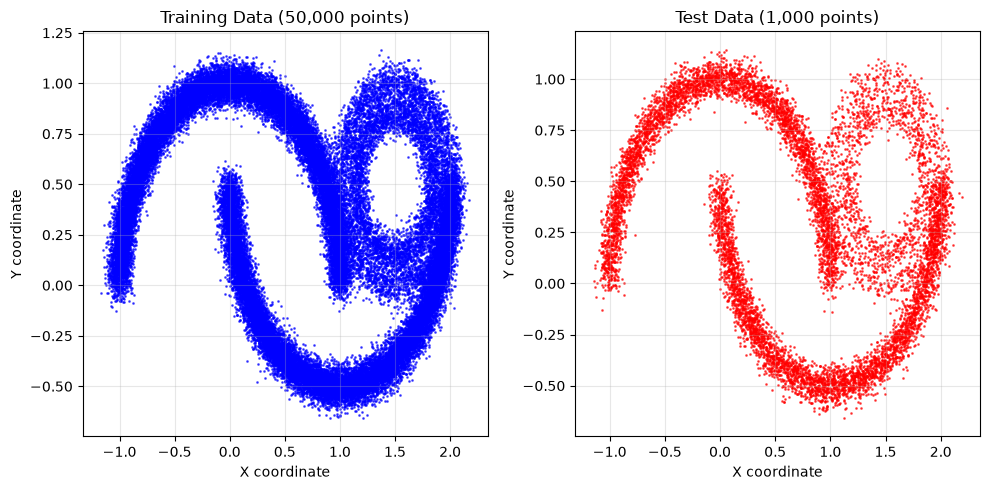

✅ Dataset created and visualized!
   Notice how the data forms two crescent moon shapes!


In [3]:
# Generate a more challenging dataset
print("🌙 Generating challenging two moons dataset...")

# Create training data (50,000 points) with more noise and complexity
train_moons = datasets.make_moons(n_samples=50000, noise=0.05)[0].astype(np.float32)
print(f"   Training moons shape: {train_moons.shape}")

# Add some additional complexity by mixing with circles data
print("🔄 Adding complexity with mixed dataset...")
train_circles = datasets.make_circles(n_samples=10000, noise=0.1, factor=0.7)[0].astype(np.float32)

# Scale and shift circles to mix with moons
train_circles = train_circles * 0.5 + np.array([1.5, 0.5])

# Mix the datasets (80% moons, 20% circles) and shuffle
train_data = np.vstack([train_moons, train_circles])
train_data = np.random.permutation(train_data)

# Split into training and test sets
train_data, test_data = train_data[:50000], train_data[50000:]

print(f"   Final training data shape: {train_data.shape}")
print("   Training dataset includes both moons and circles for added complexity!")
print(f"   Moons: {train_moons.shape[0]} samples")
print(f"   Circles: {train_circles.shape[0]} samples")
print(f"   Total: {train_data.shape[0]} samples")

# Let's visualize our data
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Training Data (50,000 points)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)

plt.scatter(test_data[:, 0], test_data[:, 1], c='red', s=1, alpha=0.6)
plt.title('Test Data (1,000 points)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Dataset created and visualized!")
print("   Notice how the data forms two crescent moon shapes!")


## Step 4: Prepare Data Loaders

Data loaders help us feed data to our model in small batches during training. This is more memory-efficient than loading all data at once.


In [4]:
# Set up data loaders for efficient batch processing
print("📦 Setting up data loaders...")

# Convert numpy arrays to PyTorch tensors with correct dtype
train_tensor = torch.from_numpy(train_data).float()  # Ensure float32

print(f"   Train tensor dtype: {train_tensor.dtype}")
print(f"   Train tensor device: {train_tensor.device}")

# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 1, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_tensor, 
    batch_size=BATCH_SIZE, 
    shuffle=True,  # Randomize order for better training
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    torch.from_numpy(test_data).float(),
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"✅ Data loaders created!")
print(f"   Training batches: {len(train_loader)}")
print(f"   Test batches: {len(test_loader)}")
print(f"   Batch size: {BATCH_SIZE}")
print(f"   Target device: {device}")

# Let's peek at one batch to see what it looks like
sample_batch = next(iter(train_loader))
print(f"   Sample batch shape: {sample_batch.shape}")
print(f"   Sample batch dtype: {sample_batch.dtype}")
print(f"   Sample batch device: {sample_batch.device}")
print(f"   Sample batch range: [{sample_batch.min():.3f}, {sample_batch.max():.3f}]")

# Let's also check the data distribution in the batch
print(f"   Sample batch contains both moons and circles data!")
print(f"   X range: [{sample_batch[:, 0].min():.3f}, {sample_batch[:, 0].max():.3f}]")
print(f"   Y range: [{sample_batch[:, 1].min():.3f}, {sample_batch[:, 1].max():.3f}]")


📦 Setting up data loaders...
   Train tensor dtype: torch.float32
   Train tensor device: cpu
✅ Data loaders created!
   Training batches: 391
   Test batches: 79
   Batch size: 128
   Target device: cuda
   Sample batch shape: torch.Size([128, 2])
   Sample batch dtype: torch.float32
   Sample batch device: cpu
   Sample batch range: [-1.004, 2.042]
   Sample batch contains both moons and circles data!
   X range: [-1.004, 2.042]
   Y range: [-0.539, 1.053]


## Step 5: Understanding the GAN Architecture

Now let's build our GAN model! The key idea is to have two competing neural networks:

### What is a Generator?
The **Generator** takes random noise as input and tries to create fake data that looks like our real data. It's like an artist trying to paint a convincing forgery.

### What is a Discriminator?
The **Discriminator** takes data (real or fake) as input and tries to determine whether it's real or fake. It's like an art expert trying to spot forgeries.

### The Adversarial Game
- Generator wants to fool the Discriminator
- Discriminator wants to catch the Generator
- They improve together in this competitive process!

Let's build them step by step:


In [5]:
class Generator(nn.Module):
    """
    Generator network that creates fake data from random noise.
    
    The Generator takes random noise as input and transforms it into
    data that should look like our real moon-shaped data.
    """
    
    def __init__(self, noise_dim, output_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: noise -> hidden
            nn.Linear(noise_dim, hidden_dim),
            nn.ReLU(),
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            # Output layer: hidden -> data
            nn.Linear(hidden_dim, output_dim),
            # No activation on output - we want raw coordinates
        )
    
    def forward(self, noise):
        """
        Transform noise into fake data.
        
        Args:
            noise: Random noise tensor of shape (batch_size, noise_dim)
        
        Returns:
            fake_data: Generated data of shape (batch_size, output_dim)
        """
        return self.net(noise)

print("✅ Generator class defined!")
print("   This network will learn to create moon-shaped data from random noise.")


✅ Generator class defined!
   This network will learn to create moon-shaped data from random noise.


In [6]:
class Discriminator(nn.Module):
    """
    Discriminator network that distinguishes between real and fake data.
    
    The Discriminator takes data (real or fake) as input and outputs
    a probability that the data is real (closer to 1) or fake (closer to 0).
    """
    
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: data -> hidden
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),  # LeakyReLU helps with gradient flow
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            # Output layer: hidden -> probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()  # Output probability between 0 and 1
        )
    
    def forward(self, data):
        """
        Classify data as real or fake.
        
        Args:
            data: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            probability: Probability that data is real (0-1)
        """
        return self.net(data)

print("✅ Discriminator class defined!")
print("   This network will learn to distinguish real from fake moon data.")


✅ Discriminator class defined!
   This network will learn to distinguish real from fake moon data.


In [7]:
# Create our Generator and Discriminator models
print("🏗️ Creating GAN models...")

# Initialize models
generator = Generator(NOISE_DIM, INPUT_DIM, HIDDEN_DIM)
discriminator = Discriminator(INPUT_DIM, HIDDEN_DIM)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print("✅ GAN models created!")
print(f"   Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"   Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"   Generator learning rate: {LR_G}")
print(f"   Discriminator learning rate: {LR_D}")
print(f"   Models moved to device: {device}")
print(f"   Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\n📋 Generator architecture:")
print(generator)
print("\n📋 Discriminator architecture:")
print(discriminator)


🏗️ Creating GAN models...
✅ GAN models created!
   Generator parameters: 132,866
   Discriminator parameters: 132,609
   Generator learning rate: 0.0002
   Discriminator learning rate: 0.0002
   Models moved to device: cuda
   Models dtype: torch.float32

📋 Generator architecture:
Generator(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): ReLU()
    (6): Linear(in_features=256, out_features=2, bias=True)
  )
)

📋 Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_f

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

print("✅ Complete visualization function defined!")
print("   This function includes both training and validation loss plots.")
print("   Validation losses are shown as dashed lines when available.")


✅ Complete visualization function defined!
   This function includes both training and validation loss plots.
   Validation losses are shown as dashed lines when available.


## Step 6: Understanding GAN Training and Loss Functions

Now let's understand how GANs are trained! This is the most important part.

### The Adversarial Loss Function

GANs use a special type of loss called **adversarial loss**:

**Discriminator Loss:**
- For real data: Discriminator should output high probability (close to 1)
- For fake data: Discriminator should output low probability (close to 0)
- Loss = -log(D(real)) - log(1 - D(fake))

**Generator Loss:**
- Generator wants Discriminator to think fake data is real
- Loss = -log(D(fake)) (we want D(fake) to be high)

### Training Process:
1. Train Discriminator on real and fake data
2. Train Generator to fool the Discriminator
3. Repeat until both networks are good at their jobs

Let's implement this:


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

print("✅ Discriminator training and evaluation functions defined!")
print("   These functions teach and evaluate the Discriminator.")


✅ Discriminator training and evaluation functions defined!
   These functions teach and evaluate the Discriminator.


In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()

print("✅ Generator training and evaluation functions defined!")
print("   These functions teach and evaluate the Generator.")


✅ Generator training and evaluation functions defined!
   These functions teach and evaluate the Generator.


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, real_data in enumerate(train_loader):
        batch_size = real_data.size(0)
        real_data = real_data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(real_data, batch_size)
        d_losses.append(d_loss)
        
        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(real_data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, real_data in enumerate(test_loader):
        batch_size = real_data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(real_data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss

print("✅ Training epoch function with validation defined!")
print("   This function coordinates the training and validation of both networks.")


✅ Training epoch function with validation defined!
   This function coordinates the training and validation of both networks.


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Generated data as numpy array
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate random noise with correct device and dtype
        noise = torch.randn(num_samples, NOISE_DIM, device=device, dtype=torch.float32)
        
        # Generate fake data
        fake_samples = generator(noise)
        
        # Convert to numpy for visualization
        fake_samples = fake_samples.cpu().numpy()
    
    return fake_samples

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

print("✅ Simplified visualization function defined!")
print("   This function shows both generated samples and training progress.")
print("   Loss plots skip the first 5 epochs to avoid big magnitude issues.")


✅ Simplified visualization function defined!
   This function shows both generated samples and training progress.
   Loss plots skip the first 5 epochs to avoid big magnitude issues.


## Step 7: Visualization and Sampling Functions

Now let's create functions to visualize our training progress and generate samples. This will help us see how well our GAN is learning!


## Step 8: Let's Train Our GAN! 🚀

Now comes the exciting part - training our GAN! We'll run through multiple epochs and watch as our Generator learns to create convincing moon-shaped data while the Discriminator becomes better at spotting fakes.


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/50000 (0%)]	D_loss: 1.384179	G_loss: 0.669557
Epoch: 1 [6400/50000 (13%)]	D_loss: 0.992353	G_loss: 0.923149
Epoch: 1 [12800/50000 (26%)]	D_loss: 0.801396	G_loss: 1.226469
Epoch: 1 [19200/50000 (38%)]	D_loss: 1.244483	G_loss: 0.840318
Epoch: 1 [25600/50000 (51%)]	D_loss: 1.795327	G_loss: 0.703402
Epoch: 1 [32000/50000 (64%)]	D_loss: 1.426856	G_loss: 0.802410
Epoch: 1 [38400/50000 (77%)]	D_loss: 1.360729	G_loss: 0.731072
Epoch: 1 [44800/50000 (90%)]	D_loss: 1.408828	G_loss: 0.680504
====> Epoch: 1 Train D_loss: 1.3324, Train G_loss: 0.8230
====> Epoch: 1 Val D_loss: 1.3932, Val G_loss: 0.6392
📈 Epoch 1 Summary:
   Train D Loss: 1.3324, Val D Loss: 1.3932
   Train G Loss: 0.8230, Val G Loss: 0.6392

📊 Epoch 2/100
----------------------------------------
Epoch: 2 [0/50000 (0%)]	D_loss: 1.389951	G_loss: 0.646416
Epoch: 2 [6400/50000 (13%)]	D_loss: 1.435264	G_loss

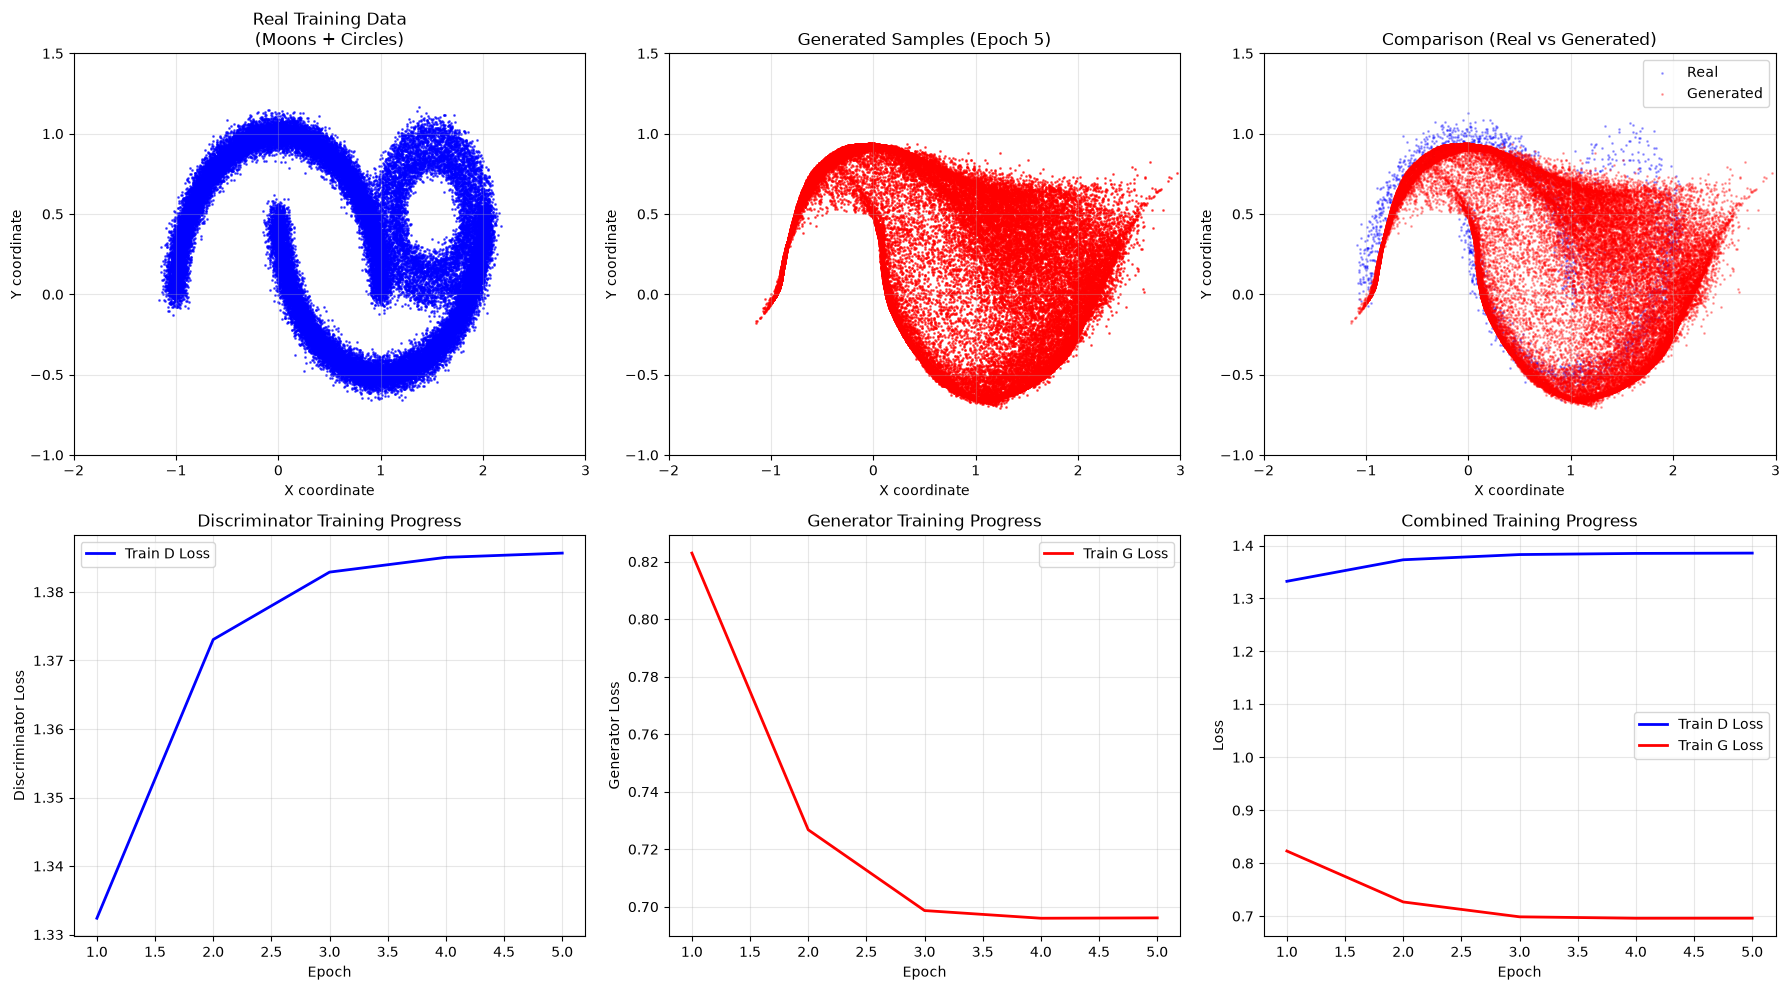

📈 Epoch 5 Summary:
   Train D Loss: 1.3857, Val D Loss: 1.3858
   Train G Loss: 0.6961, Val G Loss: 0.7262

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/50000 (0%)]	D_loss: 1.389366	G_loss: 0.722961
Epoch: 6 [6400/50000 (13%)]	D_loss: 1.384506	G_loss: 0.702101
Epoch: 6 [12800/50000 (26%)]	D_loss: 1.388003	G_loss: 0.642723
Epoch: 6 [19200/50000 (38%)]	D_loss: 1.382663	G_loss: 0.681833
Epoch: 6 [25600/50000 (51%)]	D_loss: 1.385104	G_loss: 0.707637
Epoch: 6 [32000/50000 (64%)]	D_loss: 1.398787	G_loss: 0.733512
Epoch: 6 [38400/50000 (77%)]	D_loss: 1.387695	G_loss: 0.747905
Epoch: 6 [44800/50000 (90%)]	D_loss: 1.384546	G_loss: 0.701780
====> Epoch: 6 Train D_loss: 1.3859, Train G_loss: 0.6972
====> Epoch: 6 Val D_loss: 1.3863, Val G_loss: 0.7150
📈 Epoch 6 Summary:
   Train D Loss: 1.3859, Val D Loss: 1.3863
   Train G Loss: 0.6972, Val G Loss: 0.7150

📊 Epoch 7/100
----------------------------------------
Epoch: 7 [0/50000 (0%)]	D_loss: 1.386690	G_loss: 0.694084
Epoch:

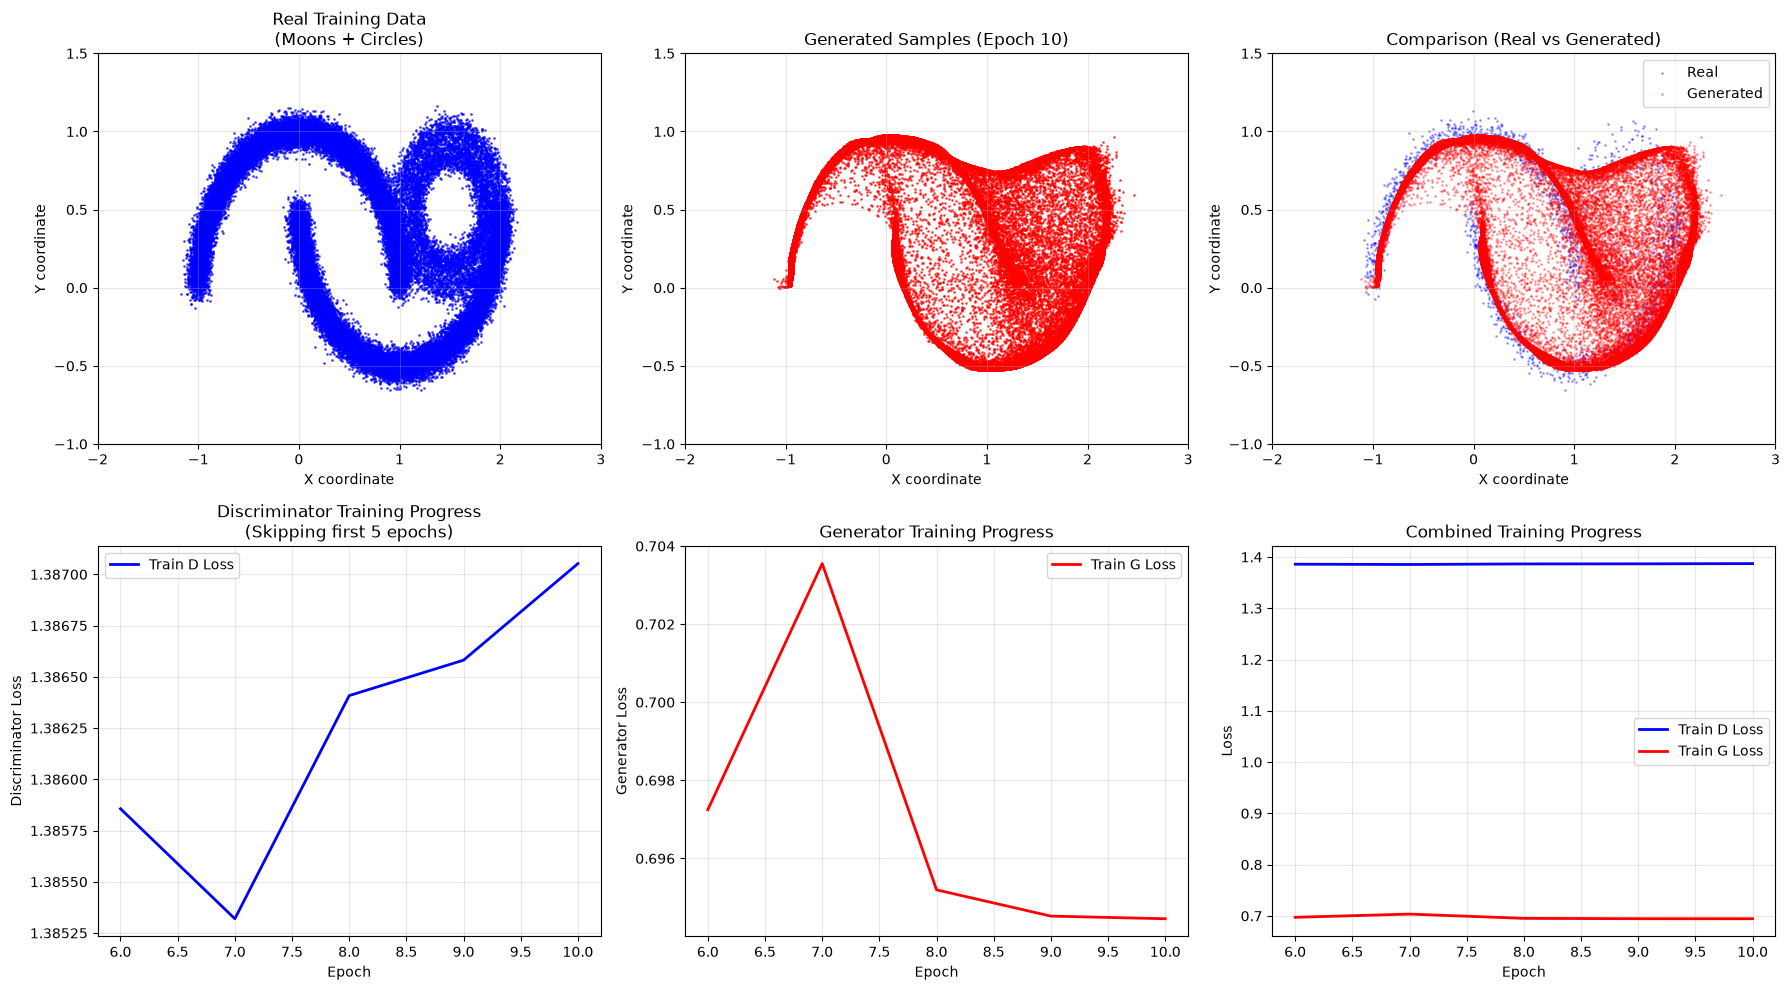

📈 Epoch 10 Summary:
   Train D Loss: 1.3871, Val D Loss: 1.3899
   Train G Loss: 0.6945, Val G Loss: 0.6769

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/50000 (0%)]	D_loss: 1.400532	G_loss: 0.698959
Epoch: 11 [6400/50000 (13%)]	D_loss: 1.390754	G_loss: 0.683828
Epoch: 11 [12800/50000 (26%)]	D_loss: 1.385201	G_loss: 0.696717
Epoch: 11 [19200/50000 (38%)]	D_loss: 1.390360	G_loss: 0.684481
Epoch: 11 [25600/50000 (51%)]	D_loss: 1.386381	G_loss: 0.706841
Epoch: 11 [32000/50000 (64%)]	D_loss: 1.382565	G_loss: 0.713691
Epoch: 11 [38400/50000 (77%)]	D_loss: 1.386262	G_loss: 0.676743
Epoch: 11 [44800/50000 (90%)]	D_loss: 1.386849	G_loss: 0.708662
====> Epoch: 11 Train D_loss: 1.3870, Train G_loss: 0.6944
====> Epoch: 11 Val D_loss: 1.3859, Val G_loss: 0.6992
📈 Epoch 11 Summary:
   Train D Loss: 1.3870, Val D Loss: 1.3859
   Train G Loss: 0.6944, Val G Loss: 0.6992

📊 Epoch 12/100
----------------------------------------
Epoch: 12 [0/50000 (0%)]	D_loss: 1.386393	G_loss: 

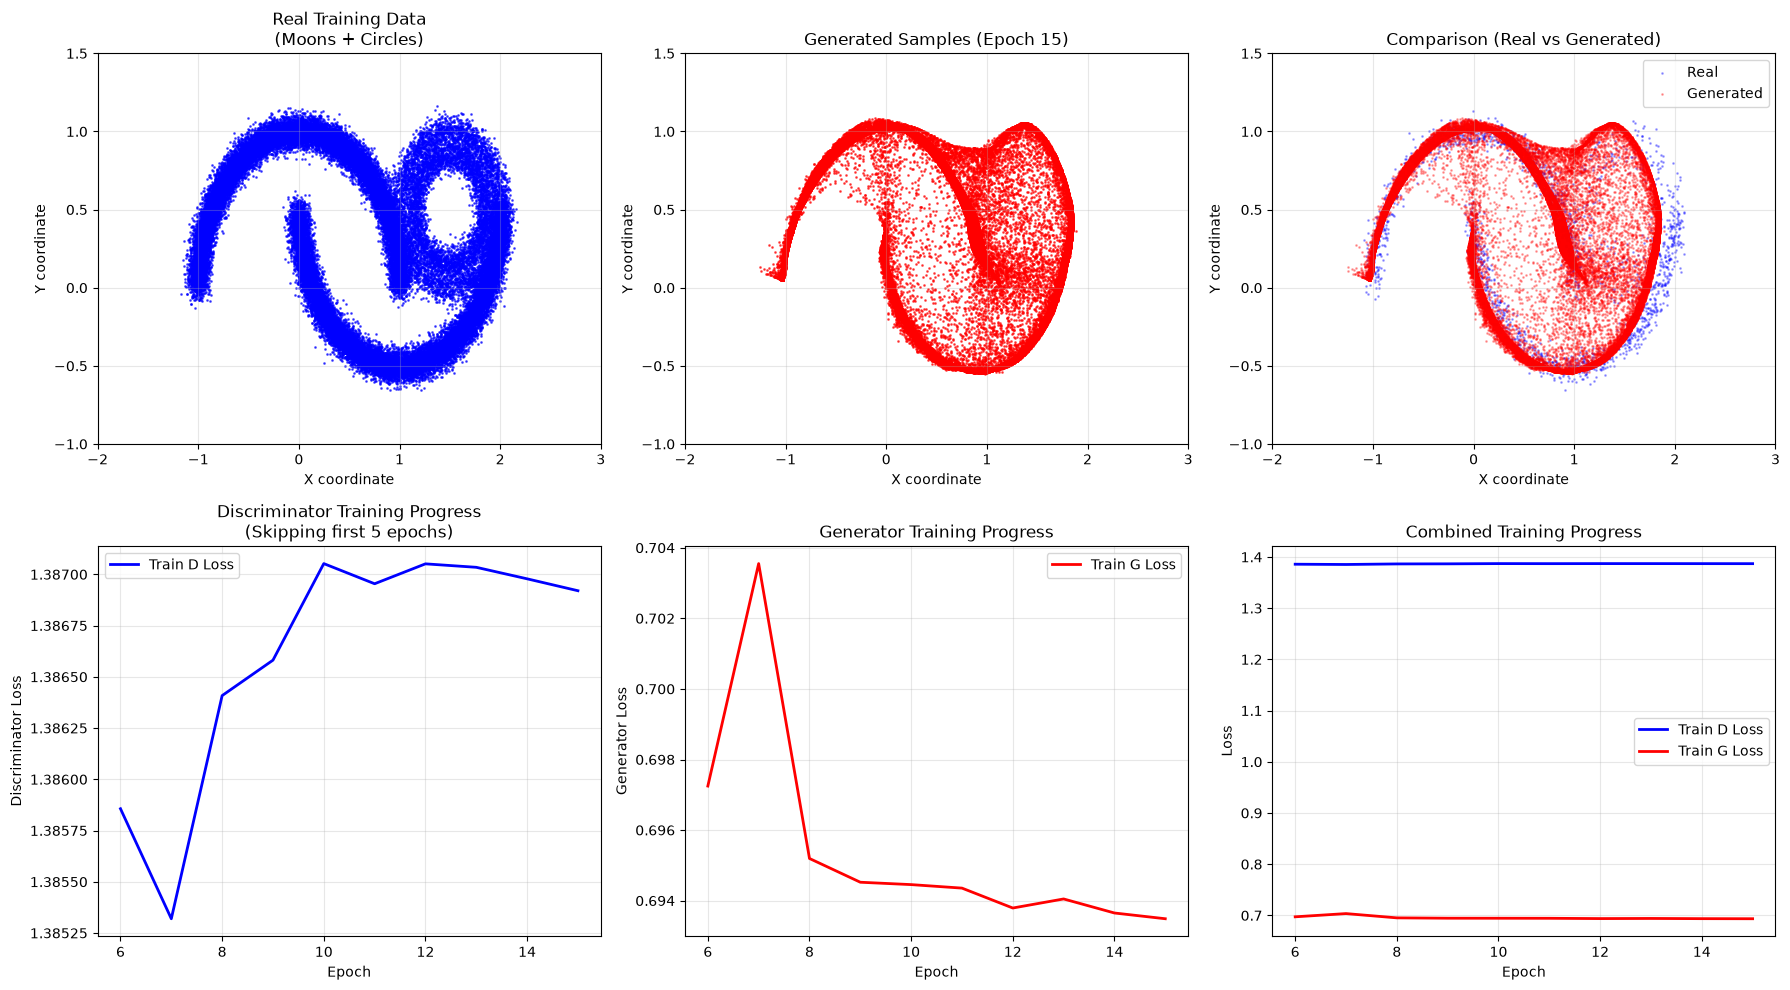

📈 Epoch 15 Summary:
   Train D Loss: 1.3869, Val D Loss: 1.3876
   Train G Loss: 0.6935, Val G Loss: 0.6959

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/50000 (0%)]	D_loss: 1.390126	G_loss: 0.694462
Epoch: 16 [6400/50000 (13%)]	D_loss: 1.386760	G_loss: 0.699148
Epoch: 16 [12800/50000 (26%)]	D_loss: 1.386792	G_loss: 0.694944
Epoch: 16 [19200/50000 (38%)]	D_loss: 1.385596	G_loss: 0.694637
Epoch: 16 [25600/50000 (51%)]	D_loss: 1.390648	G_loss: 0.691073
Epoch: 16 [32000/50000 (64%)]	D_loss: 1.384356	G_loss: 0.687124
Epoch: 16 [38400/50000 (77%)]	D_loss: 1.386543	G_loss: 0.692617
Epoch: 16 [44800/50000 (90%)]	D_loss: 1.387770	G_loss: 0.703701
====> Epoch: 16 Train D_loss: 1.3868, Train G_loss: 0.6932
====> Epoch: 16 Val D_loss: 1.3860, Val G_loss: 0.6924
📈 Epoch 16 Summary:
   Train D Loss: 1.3868, Val D Loss: 1.3860
   Train G Loss: 0.6932, Val G Loss: 0.6924

📊 Epoch 17/100
----------------------------------------
Epoch: 17 [0/50000 (0%)]	D_loss: 1.385355	G_loss: 

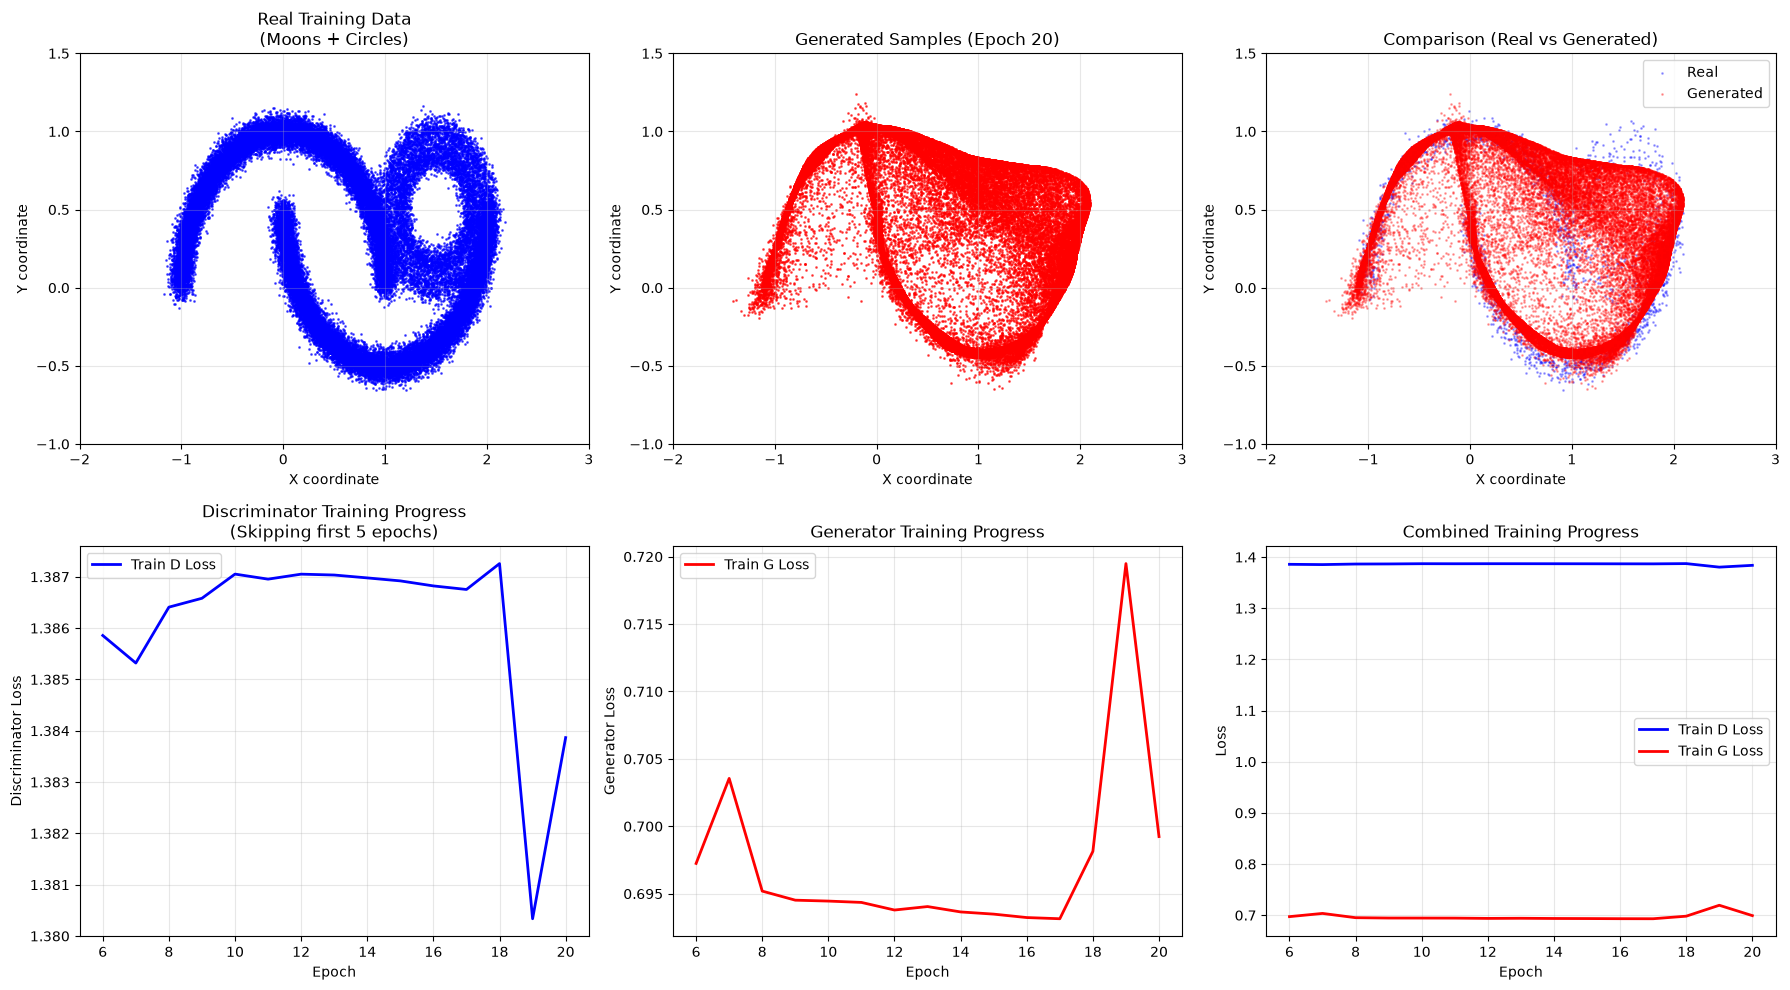

📈 Epoch 20 Summary:
   Train D Loss: 1.3839, Val D Loss: 1.3829
   Train G Loss: 0.6992, Val G Loss: 0.6983

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/50000 (0%)]	D_loss: 1.382663	G_loss: 0.699743
Epoch: 21 [6400/50000 (13%)]	D_loss: 1.382207	G_loss: 0.706509
Epoch: 21 [12800/50000 (26%)]	D_loss: 1.388120	G_loss: 0.701255
Epoch: 21 [19200/50000 (38%)]	D_loss: 1.383567	G_loss: 0.715151
Epoch: 21 [25600/50000 (51%)]	D_loss: 1.387019	G_loss: 0.689235
Epoch: 21 [32000/50000 (64%)]	D_loss: 1.387426	G_loss: 0.700703
Epoch: 21 [38400/50000 (77%)]	D_loss: 1.385161	G_loss: 0.690206
Epoch: 21 [44800/50000 (90%)]	D_loss: 1.391062	G_loss: 0.686406
====> Epoch: 21 Train D_loss: 1.3858, Train G_loss: 0.6944
====> Epoch: 21 Val D_loss: 1.3883, Val G_loss: 0.7033
📈 Epoch 21 Summary:
   Train D Loss: 1.3858, Val D Loss: 1.3883
   Train G Loss: 0.6944, Val G Loss: 0.7033

📊 Epoch 22/100
----------------------------------------
Epoch: 22 [0/50000 (0%)]	D_loss: 1.389096	G_loss: 

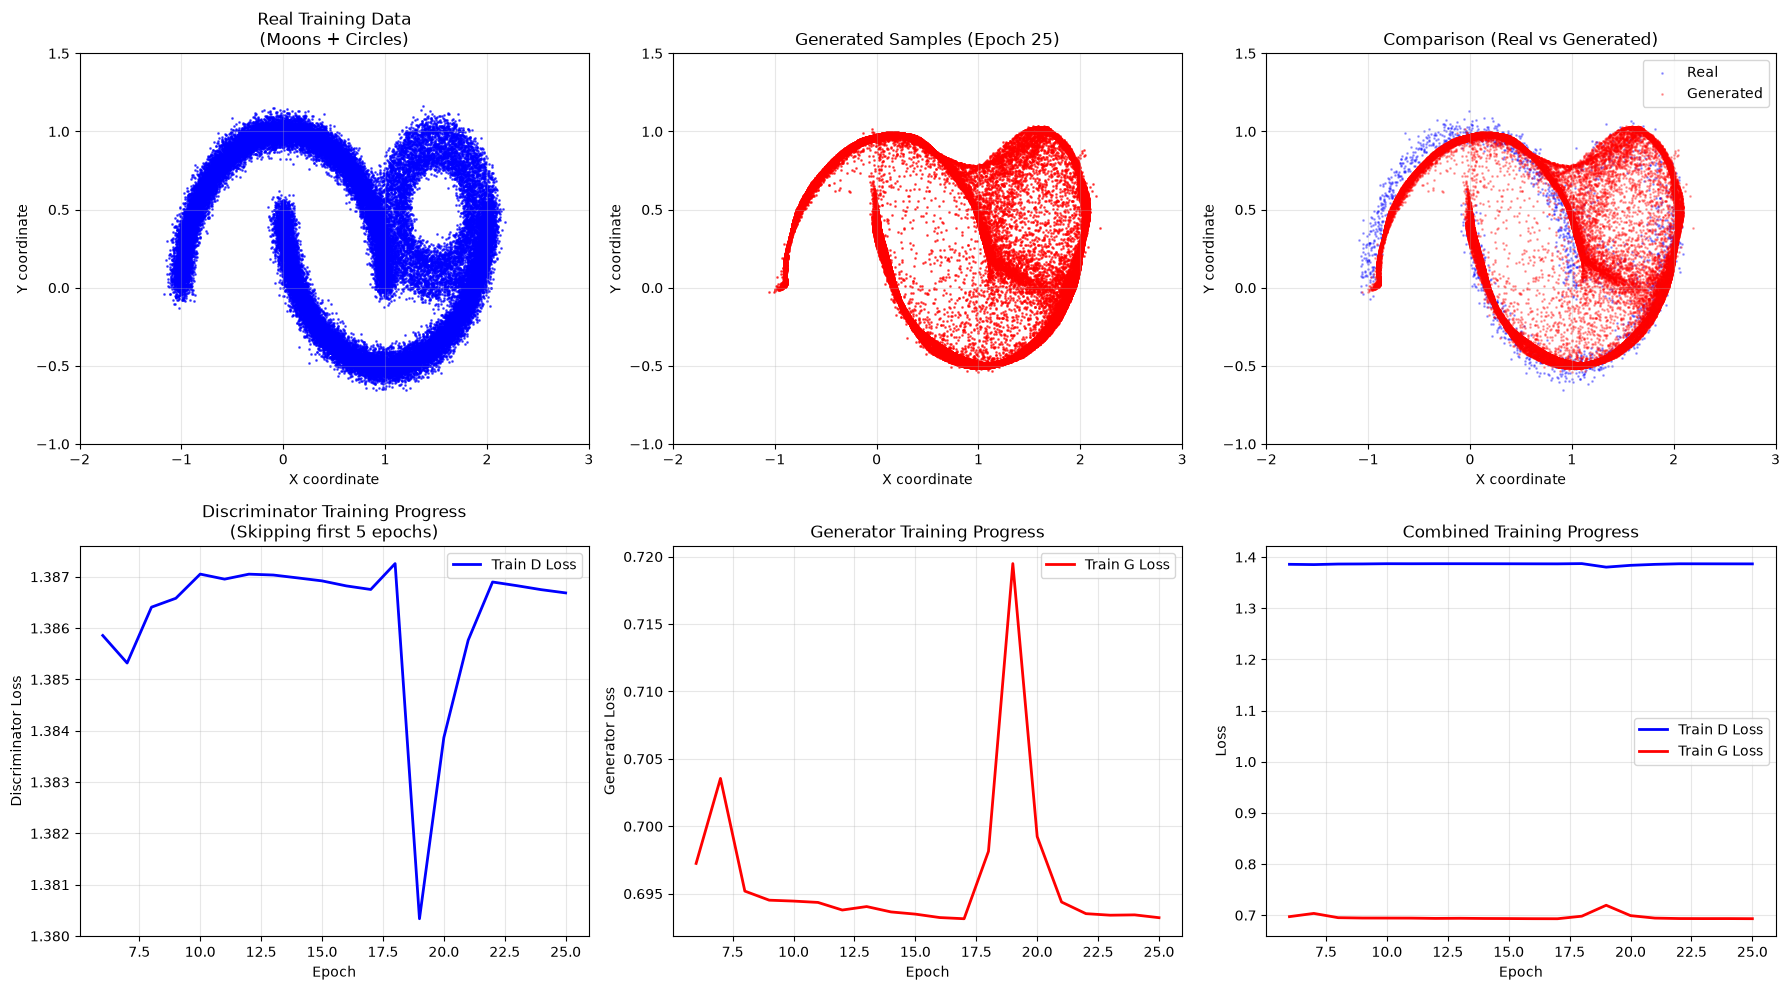

📈 Epoch 25 Summary:
   Train D Loss: 1.3867, Val D Loss: 1.3867
   Train G Loss: 0.6932, Val G Loss: 0.6876

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/50000 (0%)]	D_loss: 1.386847	G_loss: 0.689042
Epoch: 26 [6400/50000 (13%)]	D_loss: 1.386814	G_loss: 0.692617
Epoch: 26 [12800/50000 (26%)]	D_loss: 1.387131	G_loss: 0.695187
Epoch: 26 [19200/50000 (38%)]	D_loss: 1.386196	G_loss: 0.692584
Epoch: 26 [25600/50000 (51%)]	D_loss: 1.389130	G_loss: 0.688868
Epoch: 26 [32000/50000 (64%)]	D_loss: 1.385578	G_loss: 0.689184
Epoch: 26 [38400/50000 (77%)]	D_loss: 1.385929	G_loss: 0.692593
Epoch: 26 [44800/50000 (90%)]	D_loss: 1.385821	G_loss: 0.698975
====> Epoch: 26 Train D_loss: 1.3866, Train G_loss: 0.6932
====> Epoch: 26 Val D_loss: 1.3867, Val G_loss: 0.6944
📈 Epoch 26 Summary:
   Train D Loss: 1.3866, Val D Loss: 1.3867
   Train G Loss: 0.6932, Val G Loss: 0.6944

📊 Epoch 27/100
----------------------------------------
Epoch: 27 [0/50000 (0%)]	D_loss: 1.386947	G_loss: 

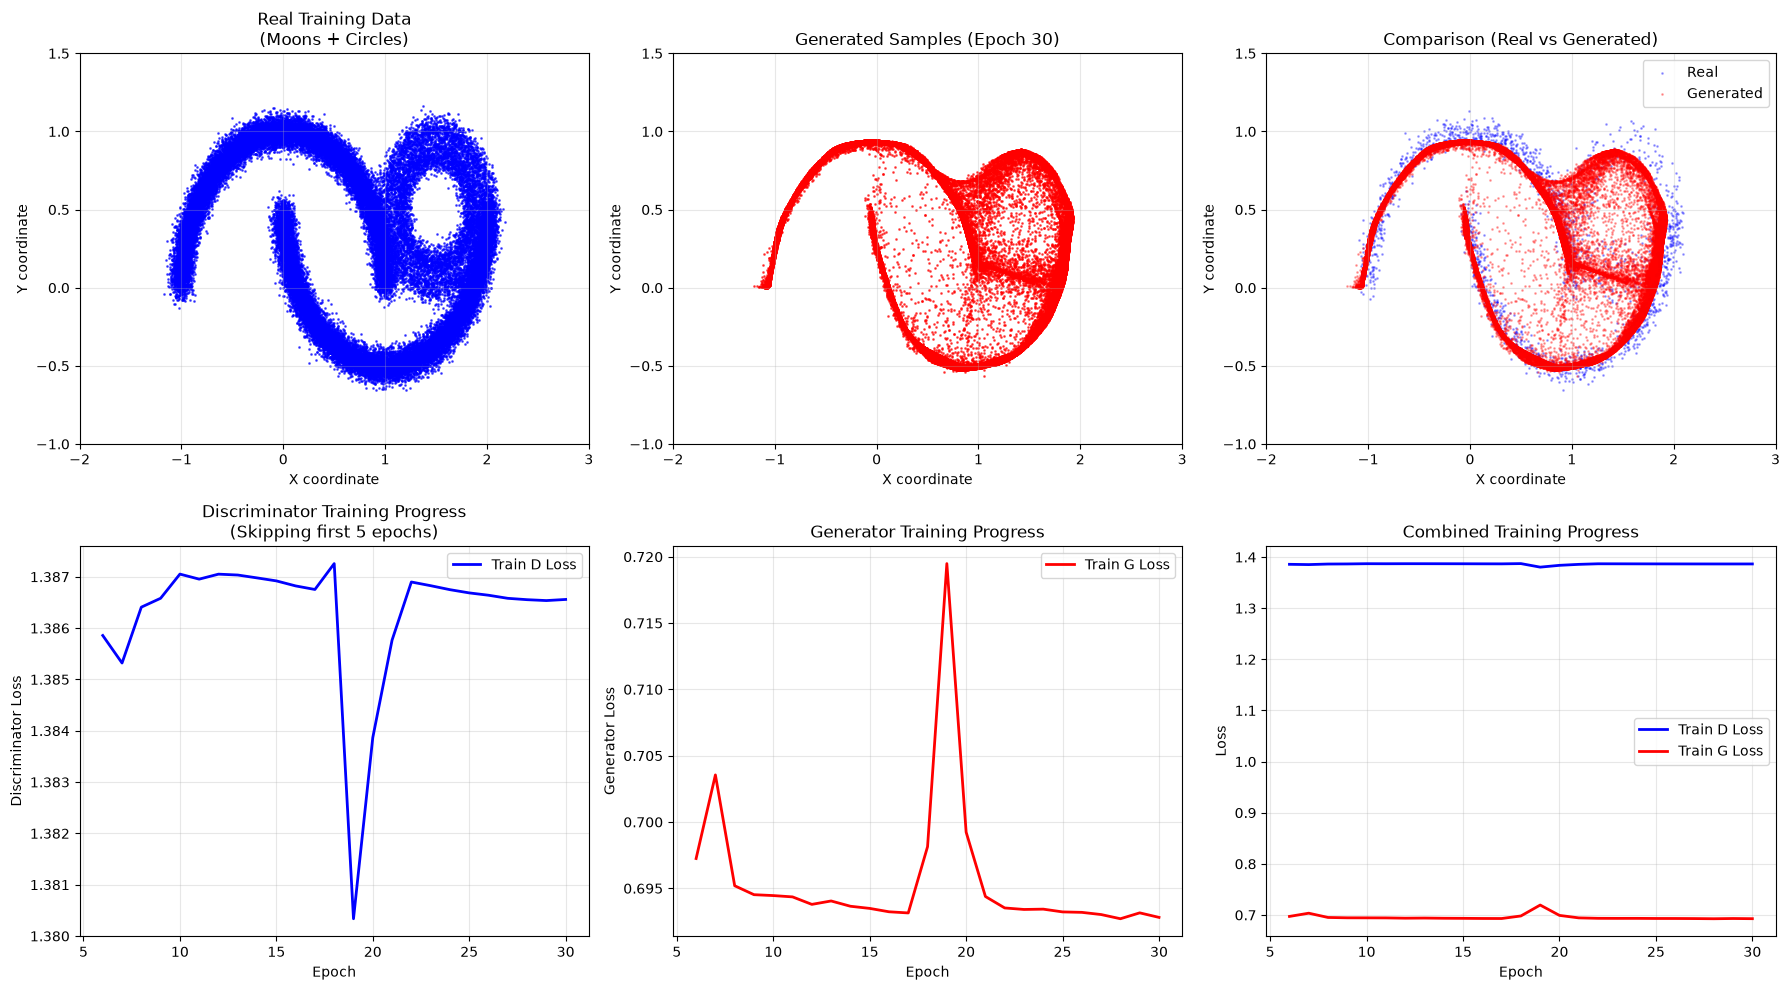

📈 Epoch 30 Summary:
   Train D Loss: 1.3866, Val D Loss: 1.3861
   Train G Loss: 0.6928, Val G Loss: 0.6924

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/50000 (0%)]	D_loss: 1.385955	G_loss: 0.692330
Epoch: 31 [6400/50000 (13%)]	D_loss: 1.386118	G_loss: 0.693160
Epoch: 31 [12800/50000 (26%)]	D_loss: 1.386272	G_loss: 0.691884
Epoch: 31 [19200/50000 (38%)]	D_loss: 1.386501	G_loss: 0.693706
Epoch: 31 [25600/50000 (51%)]	D_loss: 1.385901	G_loss: 0.691381
Epoch: 31 [32000/50000 (64%)]	D_loss: 1.386837	G_loss: 0.693667
Epoch: 31 [38400/50000 (77%)]	D_loss: 1.386745	G_loss: 0.693134
Epoch: 31 [44800/50000 (90%)]	D_loss: 1.386809	G_loss: 0.693971
====> Epoch: 31 Train D_loss: 1.3865, Train G_loss: 0.6930
====> Epoch: 31 Val D_loss: 1.3863, Val G_loss: 0.6920
📈 Epoch 31 Summary:
   Train D Loss: 1.3865, Val D Loss: 1.3863
   Train G Loss: 0.6930, Val G Loss: 0.6920

📊 Epoch 32/100
----------------------------------------
Epoch: 32 [0/50000 (0%)]	D_loss: 1.386717	G_loss: 

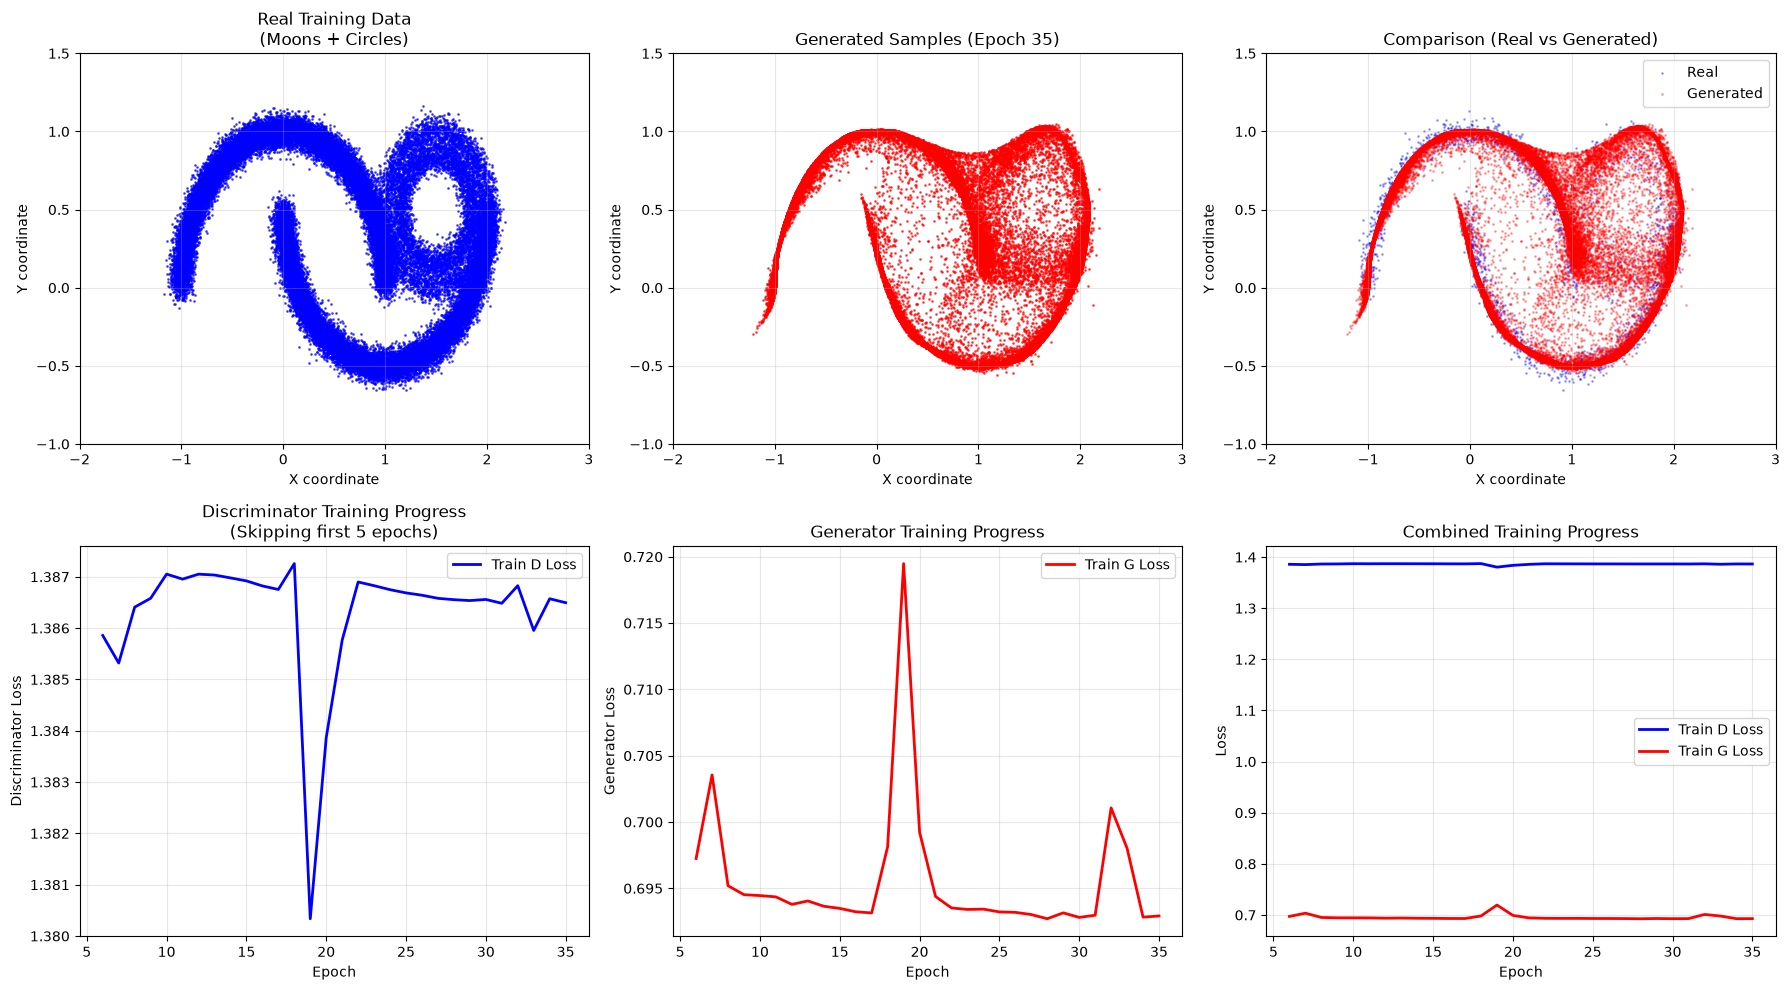

📈 Epoch 35 Summary:
   Train D Loss: 1.3865, Val D Loss: 1.3866
   Train G Loss: 0.6929, Val G Loss: 0.6912

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/50000 (0%)]	D_loss: 1.386170	G_loss: 0.691949
Epoch: 36 [6400/50000 (13%)]	D_loss: 1.386284	G_loss: 0.694575
Epoch: 36 [12800/50000 (26%)]	D_loss: 1.386469	G_loss: 0.695148
Epoch: 36 [19200/50000 (38%)]	D_loss: 1.386633	G_loss: 0.694809
Epoch: 36 [25600/50000 (51%)]	D_loss: 1.386160	G_loss: 0.694809
Epoch: 36 [32000/50000 (64%)]	D_loss: 1.386947	G_loss: 0.692309
Epoch: 36 [38400/50000 (77%)]	D_loss: 1.386362	G_loss: 0.690021
Epoch: 36 [44800/50000 (90%)]	D_loss: 1.386127	G_loss: 0.690322
====> Epoch: 36 Train D_loss: 1.3865, Train G_loss: 0.6927
====> Epoch: 36 Val D_loss: 1.3864, Val G_loss: 0.6922
📈 Epoch 36 Summary:
   Train D Loss: 1.3865, Val D Loss: 1.3864
   Train G Loss: 0.6927, Val G Loss: 0.6922

📊 Epoch 37/100
----------------------------------------
Epoch: 37 [0/50000 (0%)]	D_loss: 1.386395	G_loss: 

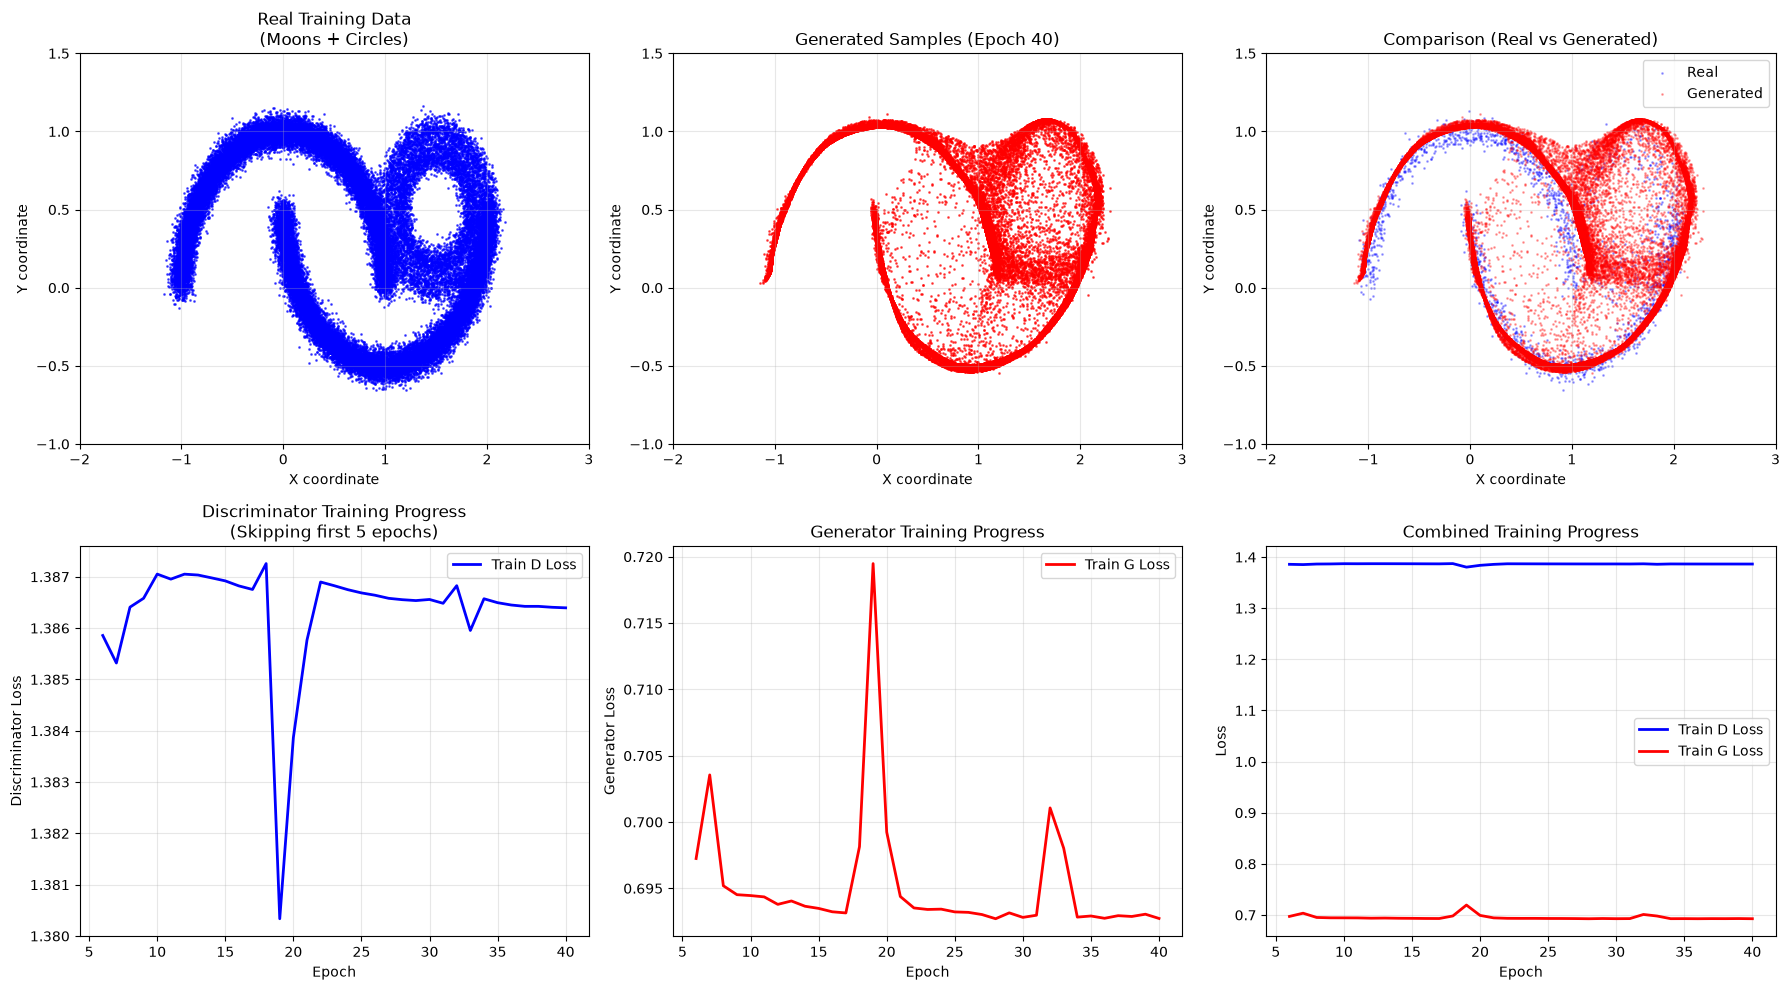

📈 Epoch 40 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3865
   Train G Loss: 0.6927, Val G Loss: 0.6937

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/50000 (0%)]	D_loss: 1.386205	G_loss: 0.694218
Epoch: 41 [6400/50000 (13%)]	D_loss: 1.386170	G_loss: 0.694119
Epoch: 41 [12800/50000 (26%)]	D_loss: 1.386555	G_loss: 0.692353
Epoch: 41 [19200/50000 (38%)]	D_loss: 1.386992	G_loss: 0.691160
Epoch: 41 [25600/50000 (51%)]	D_loss: 1.386214	G_loss: 0.692348
Epoch: 41 [32000/50000 (64%)]	D_loss: 1.386169	G_loss: 0.692523
Epoch: 41 [38400/50000 (77%)]	D_loss: 1.385947	G_loss: 0.694585
Epoch: 41 [44800/50000 (90%)]	D_loss: 1.386497	G_loss: 0.692564
====> Epoch: 41 Train D_loss: 1.3864, Train G_loss: 0.6929
====> Epoch: 41 Val D_loss: 1.3862, Val G_loss: 0.6952
📈 Epoch 41 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3862
   Train G Loss: 0.6929, Val G Loss: 0.6952

📊 Epoch 42/100
----------------------------------------
Epoch: 42 [0/50000 (0%)]	D_loss: 1.386187	G_loss: 

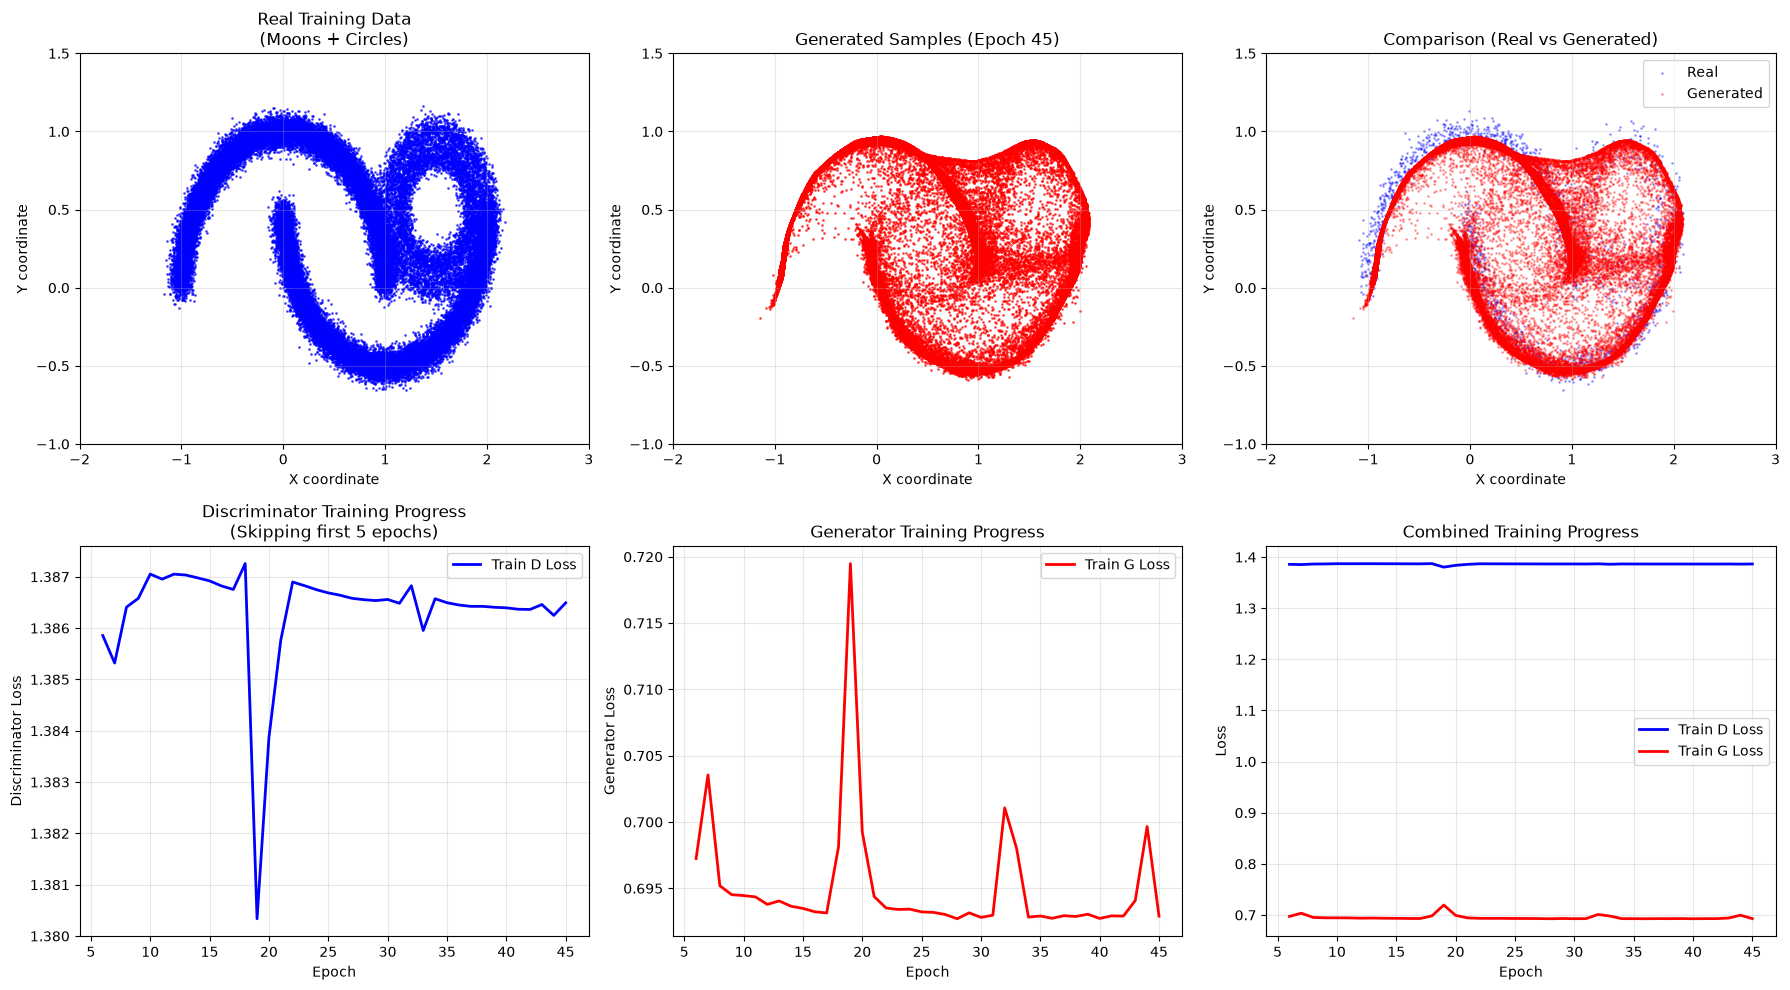

📈 Epoch 45 Summary:
   Train D Loss: 1.3865, Val D Loss: 1.3865
   Train G Loss: 0.6929, Val G Loss: 0.6907

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/50000 (0%)]	D_loss: 1.387188	G_loss: 0.691325
Epoch: 46 [6400/50000 (13%)]	D_loss: 1.386503	G_loss: 0.692159
Epoch: 46 [12800/50000 (26%)]	D_loss: 1.386623	G_loss: 0.688197
Epoch: 46 [19200/50000 (38%)]	D_loss: 1.386631	G_loss: 0.690590
Epoch: 46 [25600/50000 (51%)]	D_loss: 1.387033	G_loss: 0.694254
Epoch: 46 [32000/50000 (64%)]	D_loss: 1.386323	G_loss: 0.691712
Epoch: 46 [38400/50000 (77%)]	D_loss: 1.385731	G_loss: 0.685121
Epoch: 46 [44800/50000 (90%)]	D_loss: 1.385796	G_loss: 0.699967
====> Epoch: 46 Train D_loss: 1.3865, Train G_loss: 0.6925
====> Epoch: 46 Val D_loss: 1.3865, Val G_loss: 0.6989
📈 Epoch 46 Summary:
   Train D Loss: 1.3865, Val D Loss: 1.3865
   Train G Loss: 0.6925, Val G Loss: 0.6989

📊 Epoch 47/100
----------------------------------------
Epoch: 47 [0/50000 (0%)]	D_loss: 1.386496	G_loss: 

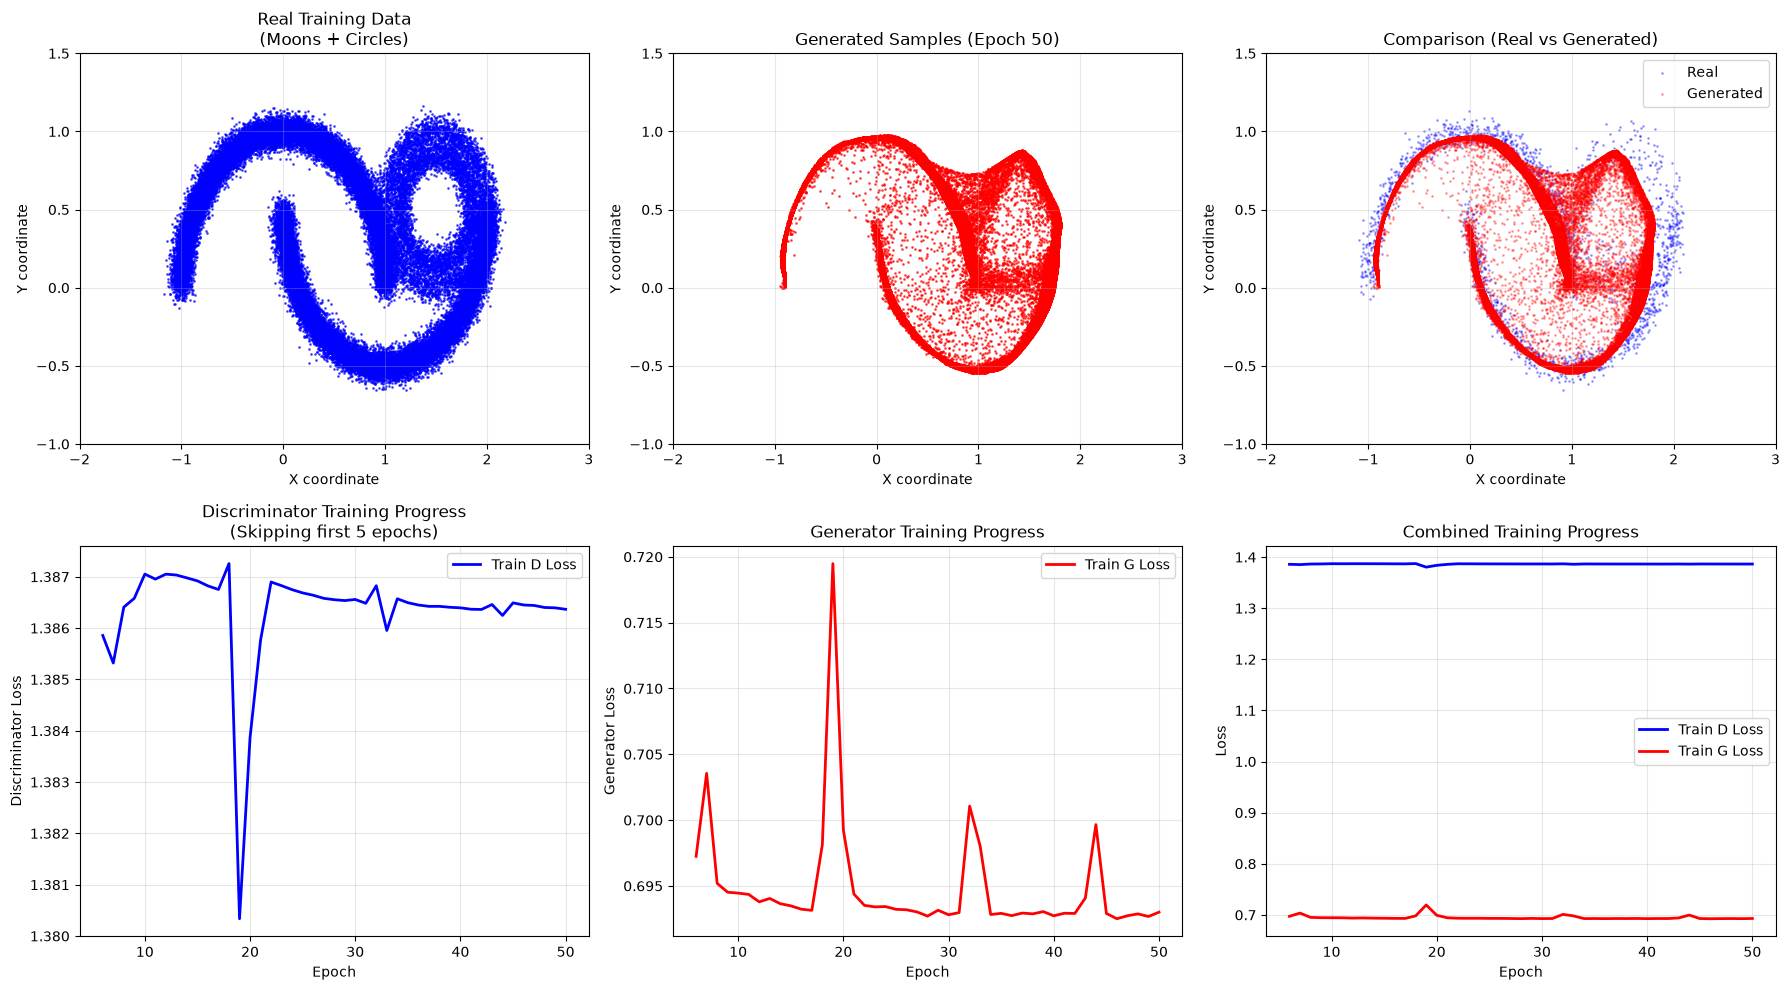

📈 Epoch 50 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3864
   Train G Loss: 0.6930, Val G Loss: 0.6940

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/50000 (0%)]	D_loss: 1.386398	G_loss: 0.693681
Epoch: 51 [6400/50000 (13%)]	D_loss: 1.386418	G_loss: 0.692459
Epoch: 51 [12800/50000 (26%)]	D_loss: 1.386239	G_loss: 0.694196
Epoch: 51 [19200/50000 (38%)]	D_loss: 1.385962	G_loss: 0.688686
Epoch: 51 [25600/50000 (51%)]	D_loss: 1.386357	G_loss: 0.692906
Epoch: 51 [32000/50000 (64%)]	D_loss: 1.386235	G_loss: 0.692550
Epoch: 51 [38400/50000 (77%)]	D_loss: 1.386286	G_loss: 0.693054
Epoch: 51 [44800/50000 (90%)]	D_loss: 1.386155	G_loss: 0.695454
====> Epoch: 51 Train D_loss: 1.3863, Train G_loss: 0.6928
====> Epoch: 51 Val D_loss: 1.3864, Val G_loss: 0.6911
📈 Epoch 51 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6928, Val G Loss: 0.6911

📊 Epoch 52/100
----------------------------------------
Epoch: 52 [0/50000 (0%)]	D_loss: 1.386917	G_loss: 

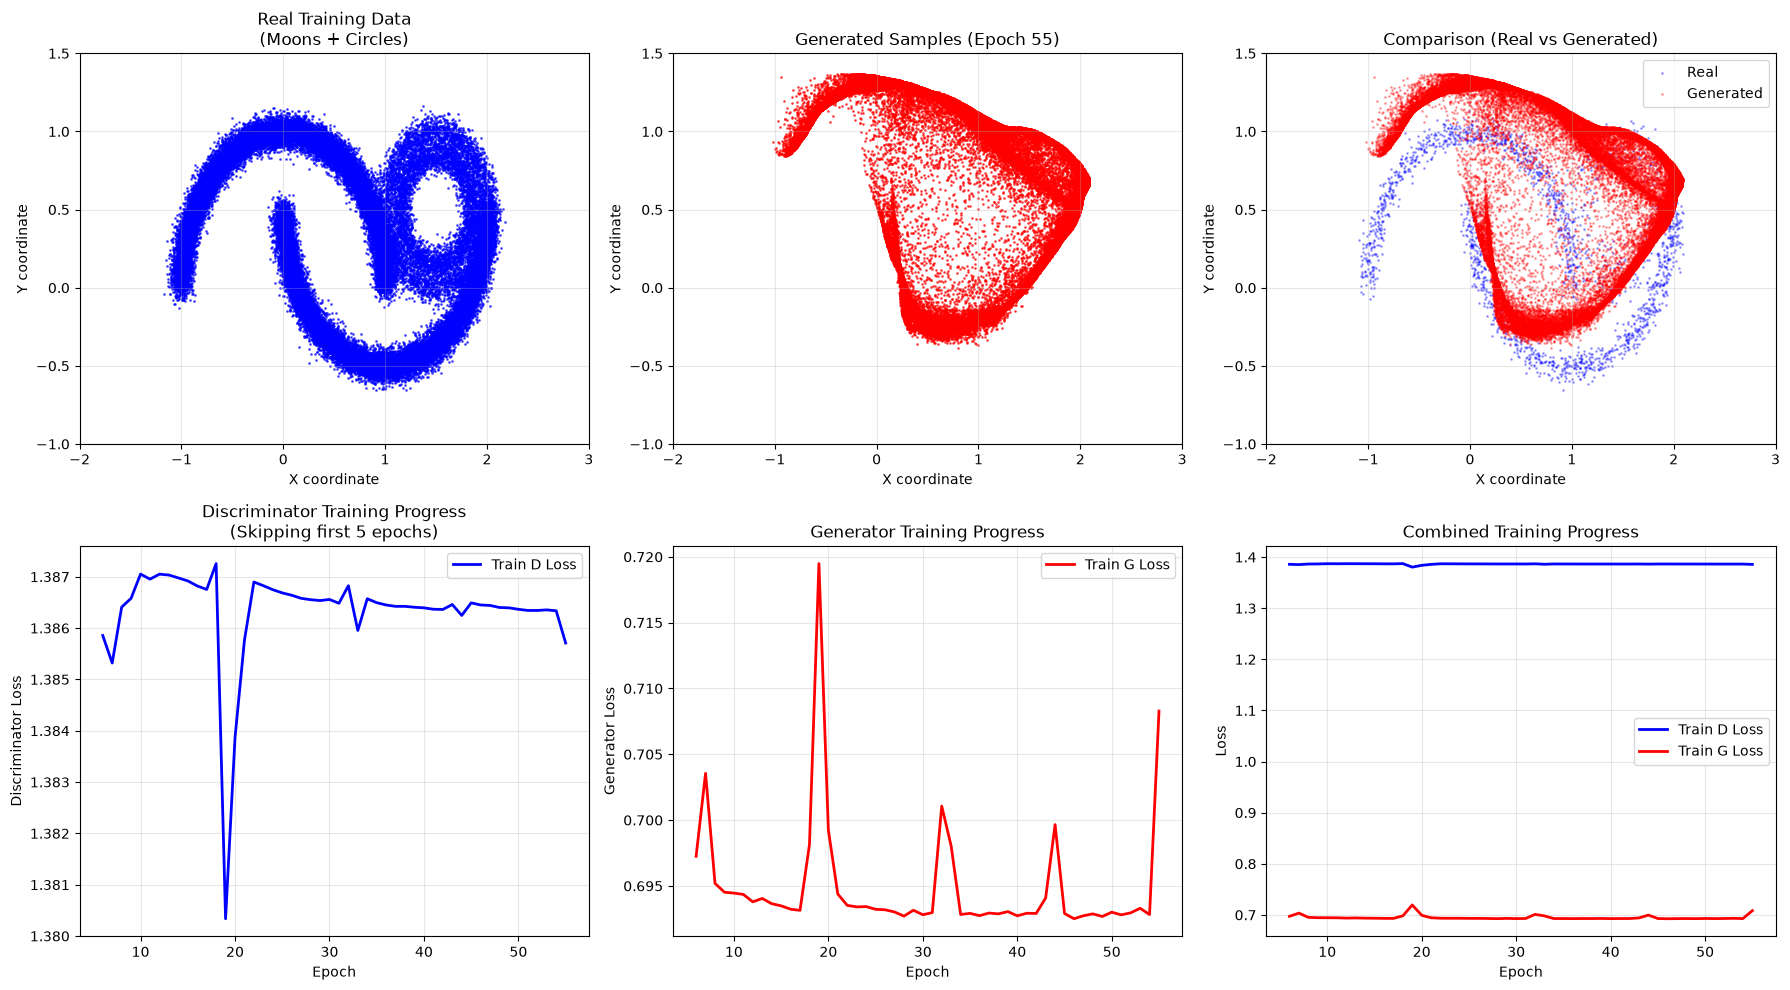

📈 Epoch 55 Summary:
   Train D Loss: 1.3857, Val D Loss: 1.3899
   Train G Loss: 0.7083, Val G Loss: 0.7448

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/50000 (0%)]	D_loss: 1.389618	G_loss: 0.758537
Epoch: 56 [6400/50000 (13%)]	D_loss: 1.388227	G_loss: 0.715700
Epoch: 56 [12800/50000 (26%)]	D_loss: 1.386003	G_loss: 0.702743
Epoch: 56 [19200/50000 (38%)]	D_loss: 1.384848	G_loss: 0.696734
Epoch: 56 [25600/50000 (51%)]	D_loss: 1.387385	G_loss: 0.677527
Epoch: 56 [32000/50000 (64%)]	D_loss: 1.386580	G_loss: 0.705683
Epoch: 56 [38400/50000 (77%)]	D_loss: 1.385838	G_loss: 0.692470
Epoch: 56 [44800/50000 (90%)]	D_loss: 1.385984	G_loss: 0.690971
====> Epoch: 56 Train D_loss: 1.3860, Train G_loss: 0.6955
====> Epoch: 56 Val D_loss: 1.3863, Val G_loss: 0.7140
📈 Epoch 56 Summary:
   Train D Loss: 1.3860, Val D Loss: 1.3863
   Train G Loss: 0.6955, Val G Loss: 0.7140

📊 Epoch 57/100
----------------------------------------
Epoch: 57 [0/50000 (0%)]	D_loss: 1.387129	G_loss: 

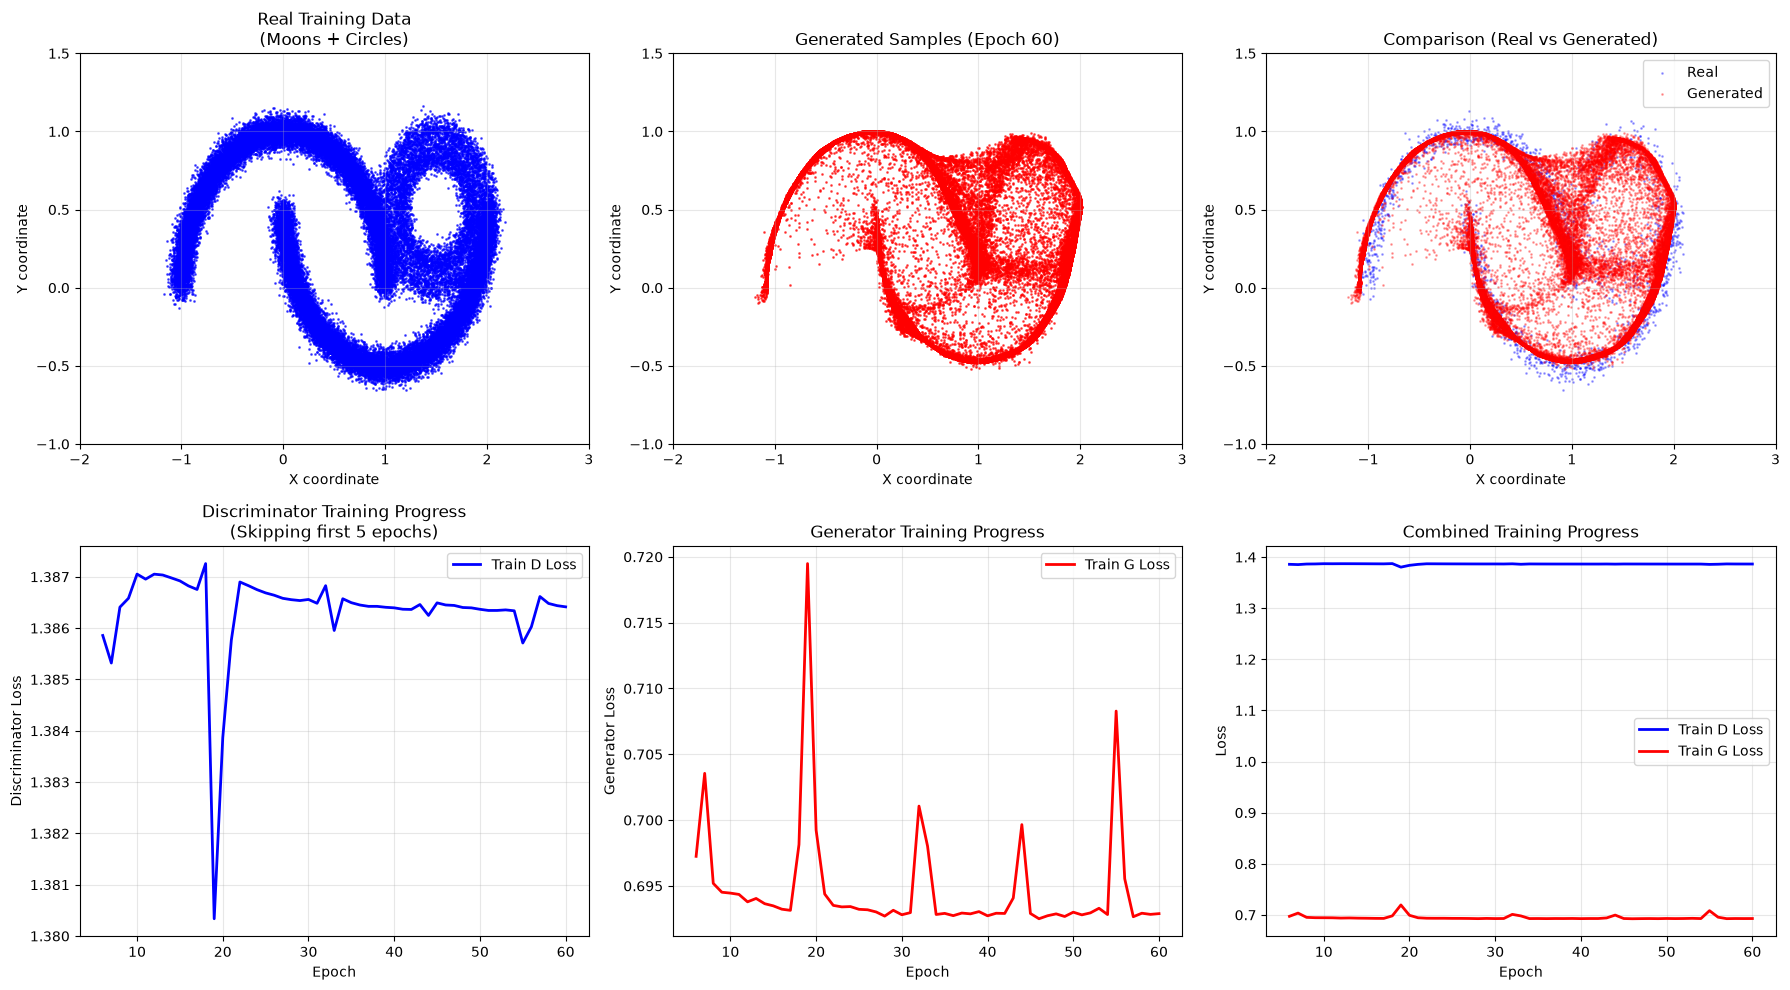

📈 Epoch 60 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3864
   Train G Loss: 0.6929, Val G Loss: 0.6947

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/50000 (0%)]	D_loss: 1.386841	G_loss: 0.693374
Epoch: 61 [6400/50000 (13%)]	D_loss: 1.386600	G_loss: 0.687928
Epoch: 61 [12800/50000 (26%)]	D_loss: 1.385977	G_loss: 0.693975
Epoch: 61 [19200/50000 (38%)]	D_loss: 1.385821	G_loss: 0.694740
Epoch: 61 [25600/50000 (51%)]	D_loss: 1.386271	G_loss: 0.698660
Epoch: 61 [32000/50000 (64%)]	D_loss: 1.386135	G_loss: 0.698648
Epoch: 61 [38400/50000 (77%)]	D_loss: 1.386557	G_loss: 0.690803
Epoch: 61 [44800/50000 (90%)]	D_loss: 1.386438	G_loss: 0.693927
====> Epoch: 61 Train D_loss: 1.3864, Train G_loss: 0.6927
====> Epoch: 61 Val D_loss: 1.3865, Val G_loss: 0.6887
📈 Epoch 61 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3865
   Train G Loss: 0.6927, Val G Loss: 0.6887

📊 Epoch 62/100
----------------------------------------
Epoch: 62 [0/50000 (0%)]	D_loss: 1.387132	G_loss: 

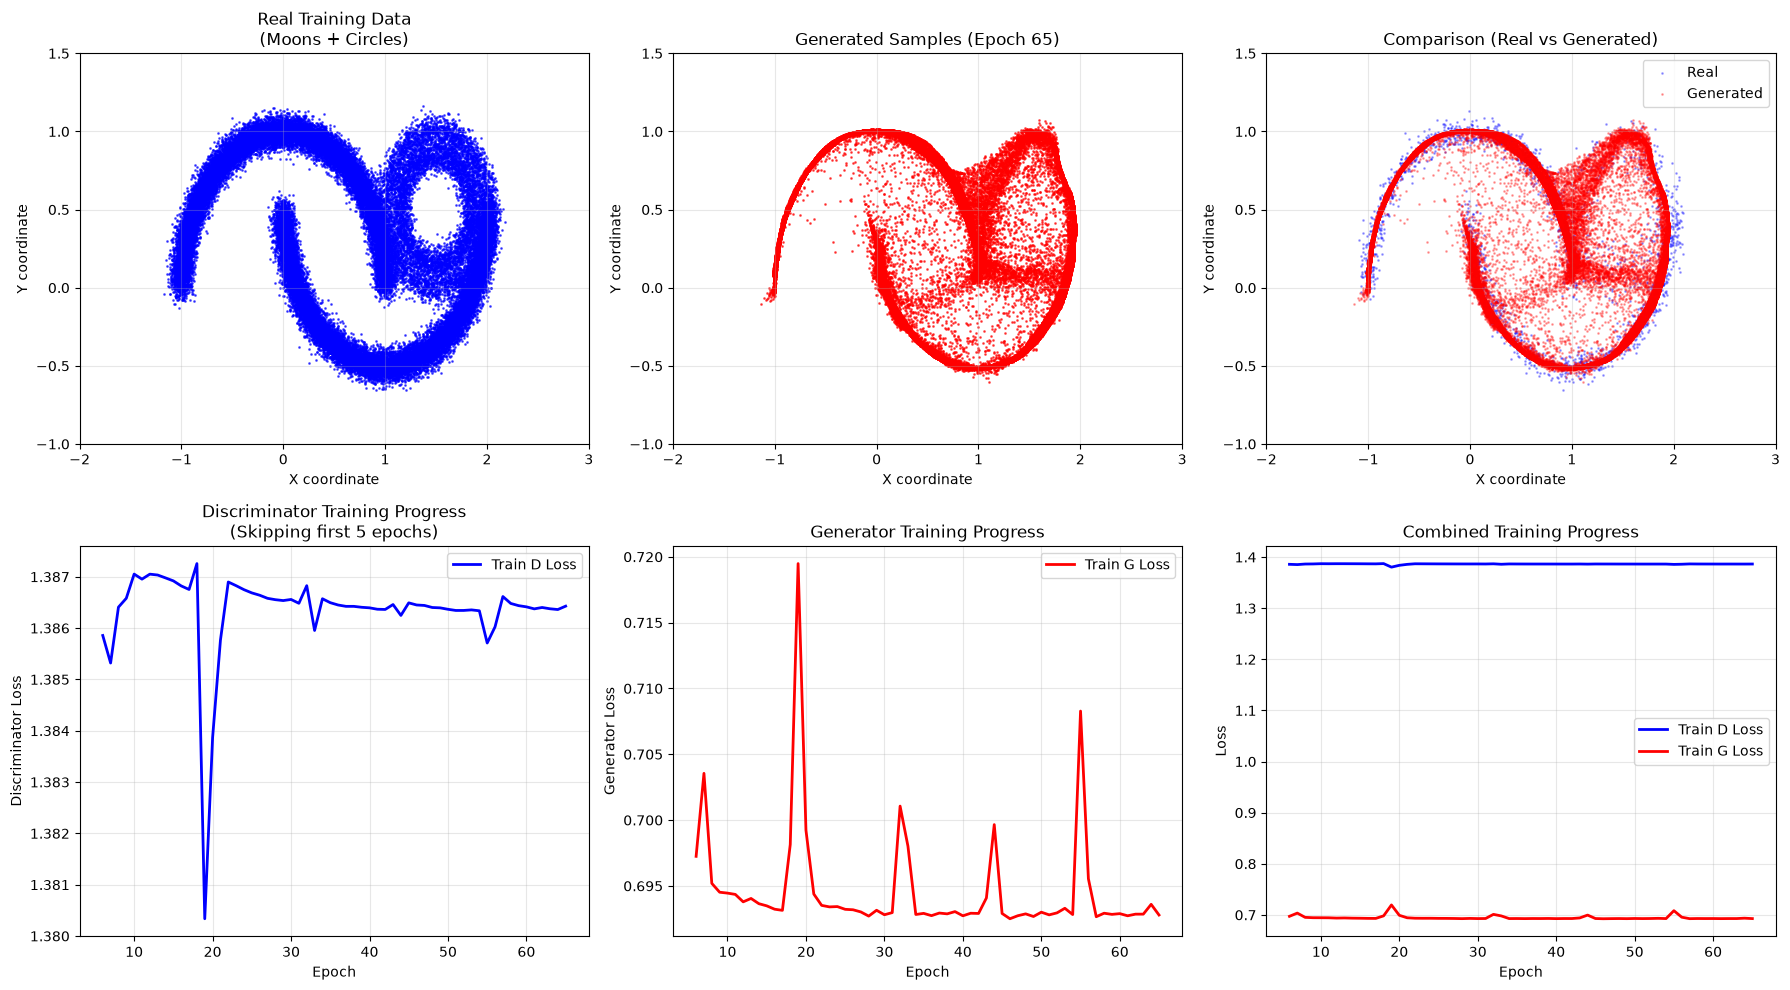

📈 Epoch 65 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3863
   Train G Loss: 0.6928, Val G Loss: 0.6904

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/50000 (0%)]	D_loss: 1.386276	G_loss: 0.690018
Epoch: 66 [6400/50000 (13%)]	D_loss: 1.385931	G_loss: 0.687574
Epoch: 66 [12800/50000 (26%)]	D_loss: 1.386176	G_loss: 0.687228
Epoch: 66 [19200/50000 (38%)]	D_loss: 1.386357	G_loss: 0.694134
Epoch: 66 [25600/50000 (51%)]	D_loss: 1.386115	G_loss: 0.692563
Epoch: 66 [32000/50000 (64%)]	D_loss: 1.386131	G_loss: 0.687461
Epoch: 66 [38400/50000 (77%)]	D_loss: 1.386361	G_loss: 0.690928
Epoch: 66 [44800/50000 (90%)]	D_loss: 1.386376	G_loss: 0.692919
====> Epoch: 66 Train D_loss: 1.3864, Train G_loss: 0.6928
====> Epoch: 66 Val D_loss: 1.3863, Val G_loss: 0.6982
📈 Epoch 66 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3863
   Train G Loss: 0.6928, Val G Loss: 0.6982

📊 Epoch 67/100
----------------------------------------
Epoch: 67 [0/50000 (0%)]	D_loss: 1.386779	G_loss: 

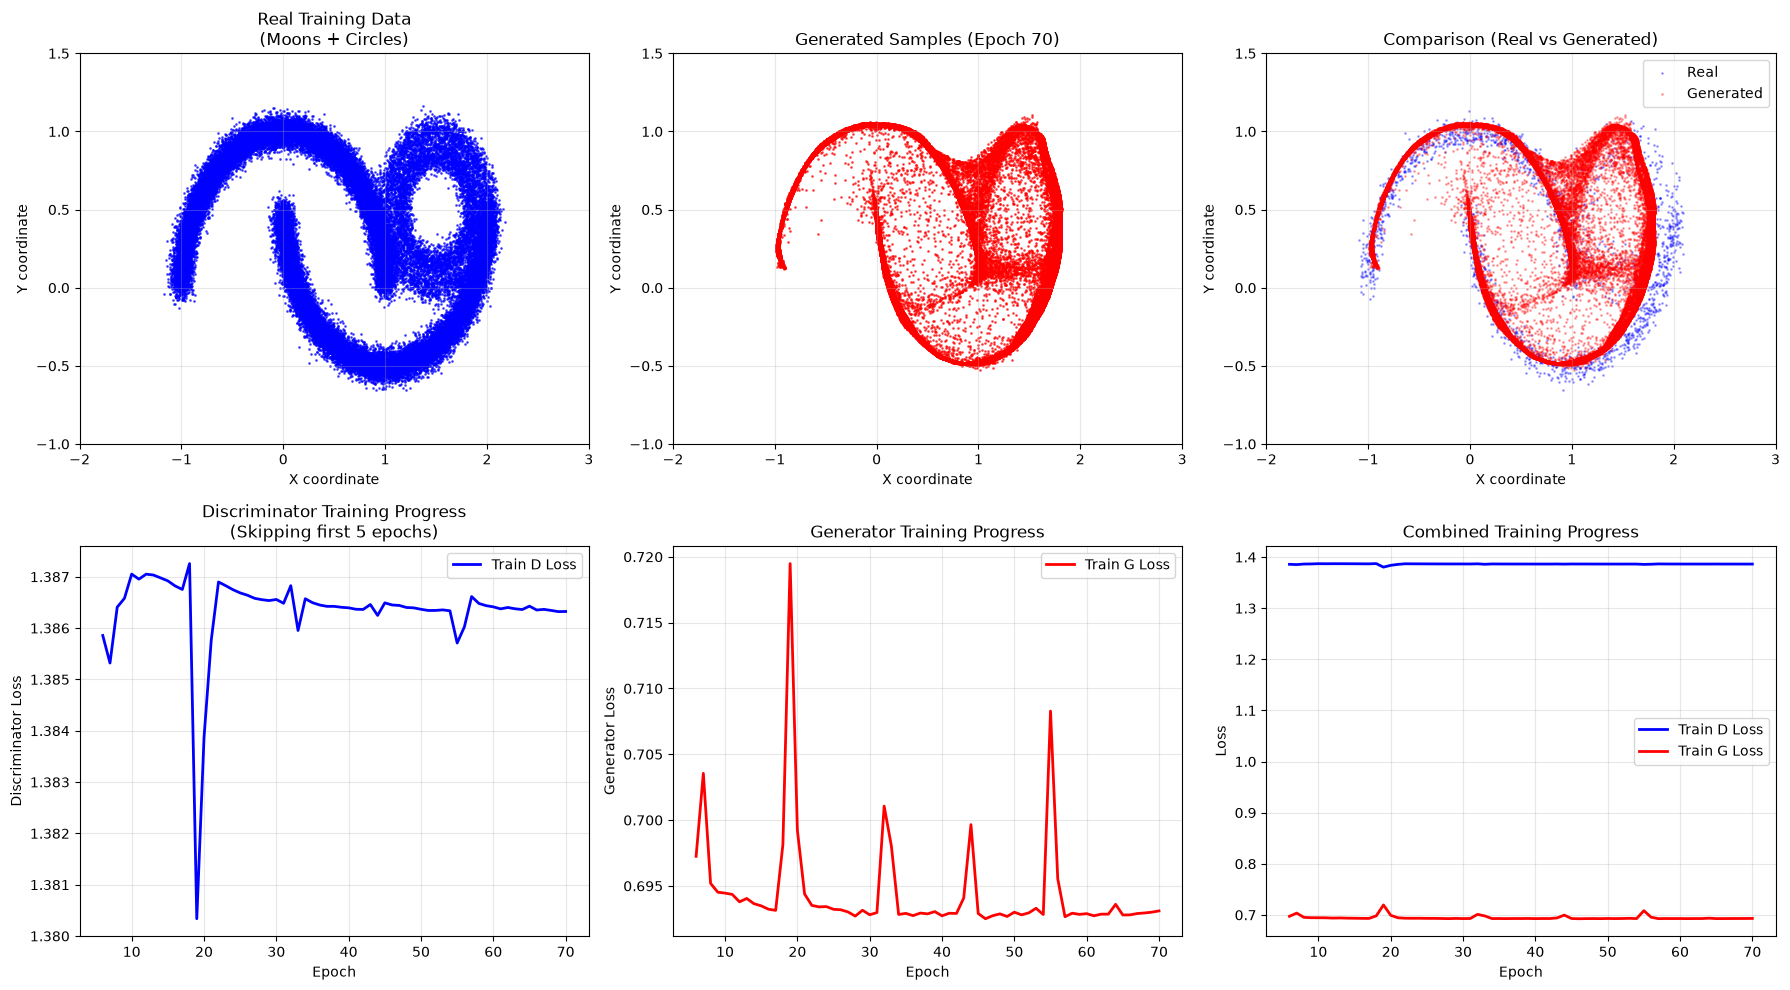

📈 Epoch 70 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6931, Val G Loss: 0.6938

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/50000 (0%)]	D_loss: 1.386304	G_loss: 0.693492
Epoch: 71 [6400/50000 (13%)]	D_loss: 1.385739	G_loss: 0.687911
Epoch: 71 [12800/50000 (26%)]	D_loss: 1.386274	G_loss: 0.692633
Epoch: 71 [19200/50000 (38%)]	D_loss: 1.386237	G_loss: 0.691190
Epoch: 71 [25600/50000 (51%)]	D_loss: 1.386400	G_loss: 0.691622
Epoch: 71 [32000/50000 (64%)]	D_loss: 1.386580	G_loss: 0.692010
Epoch: 71 [38400/50000 (77%)]	D_loss: 1.386464	G_loss: 0.693082
Epoch: 71 [44800/50000 (90%)]	D_loss: 1.386605	G_loss: 0.687188
====> Epoch: 71 Train D_loss: 1.3863, Train G_loss: 0.6930
====> Epoch: 71 Val D_loss: 1.3863, Val G_loss: 0.7005
📈 Epoch 71 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6930, Val G Loss: 0.7005

📊 Epoch 72/100
----------------------------------------
Epoch: 72 [0/50000 (0%)]	D_loss: 1.386406	G_loss: 

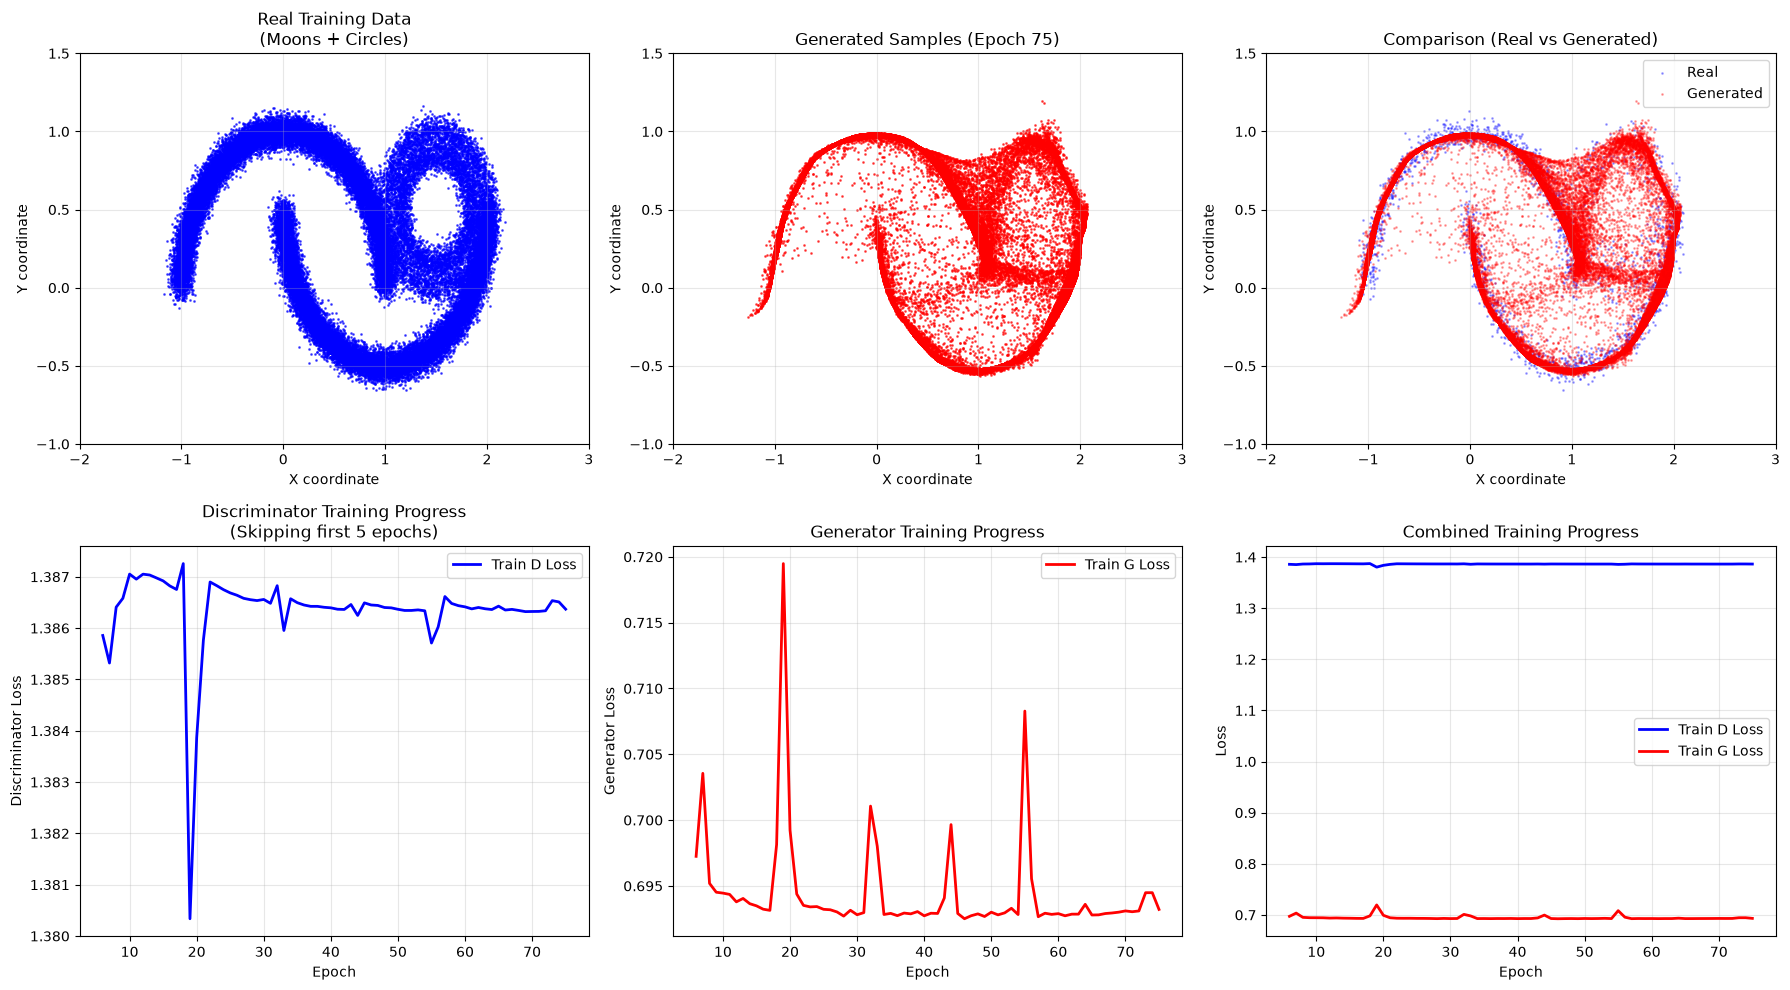

📈 Epoch 75 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6832

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/50000 (0%)]	D_loss: 1.386630	G_loss: 0.684049
Epoch: 76 [6400/50000 (13%)]	D_loss: 1.386604	G_loss: 0.693297
Epoch: 76 [12800/50000 (26%)]	D_loss: 1.386375	G_loss: 0.695655
Epoch: 76 [19200/50000 (38%)]	D_loss: 1.385947	G_loss: 0.694314
Epoch: 76 [25600/50000 (51%)]	D_loss: 1.386493	G_loss: 0.694305
Epoch: 76 [32000/50000 (64%)]	D_loss: 1.386187	G_loss: 0.696968
Epoch: 76 [38400/50000 (77%)]	D_loss: 1.386261	G_loss: 0.690543
Epoch: 76 [44800/50000 (90%)]	D_loss: 1.387042	G_loss: 0.686976
====> Epoch: 76 Train D_loss: 1.3863, Train G_loss: 0.6930
====> Epoch: 76 Val D_loss: 1.3864, Val G_loss: 0.6912
📈 Epoch 76 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6930, Val G Loss: 0.6912

📊 Epoch 77/100
----------------------------------------
Epoch: 77 [0/50000 (0%)]	D_loss: 1.386330	G_loss: 

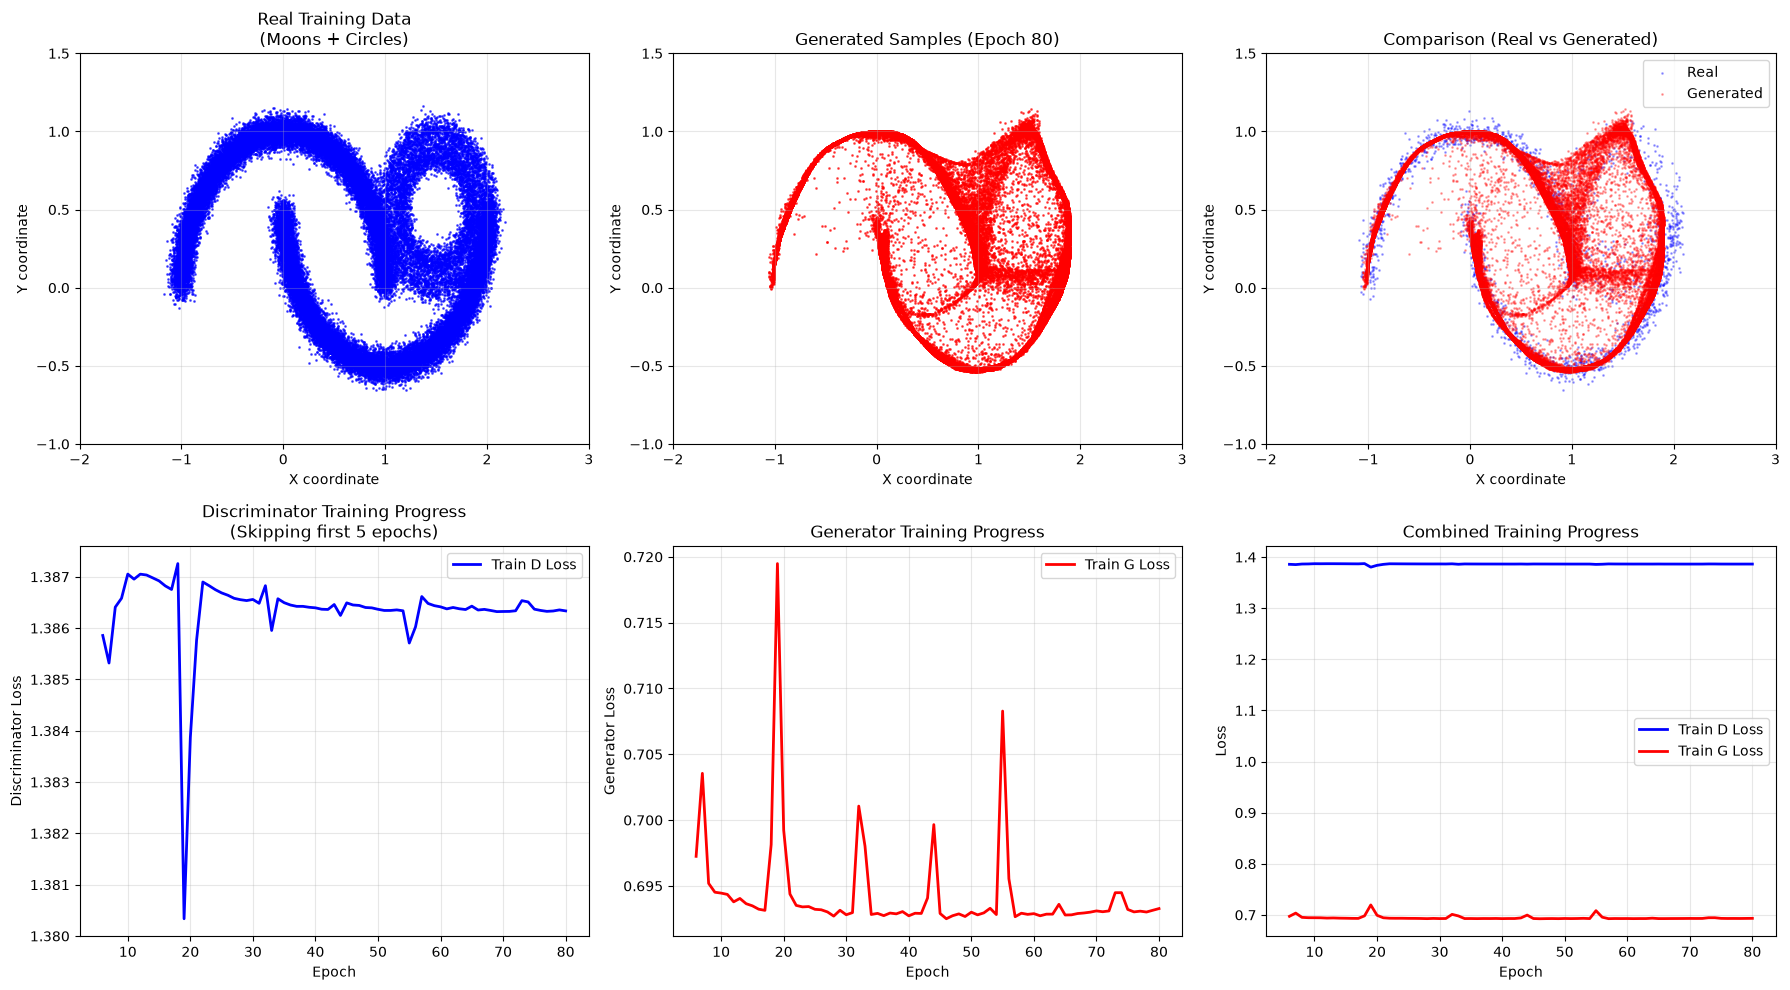

📈 Epoch 80 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6933, Val G Loss: 0.6925

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/50000 (0%)]	D_loss: 1.386364	G_loss: 0.692610
Epoch: 81 [6400/50000 (13%)]	D_loss: 1.386255	G_loss: 0.692681
Epoch: 81 [12800/50000 (26%)]	D_loss: 1.386257	G_loss: 0.693630
Epoch: 81 [19200/50000 (38%)]	D_loss: 1.386260	G_loss: 0.693768
Epoch: 81 [25600/50000 (51%)]	D_loss: 1.386439	G_loss: 0.693822
Epoch: 81 [32000/50000 (64%)]	D_loss: 1.386648	G_loss: 0.691805
Epoch: 81 [38400/50000 (77%)]	D_loss: 1.386283	G_loss: 0.692634
Epoch: 81 [44800/50000 (90%)]	D_loss: 1.386722	G_loss: 0.694456
====> Epoch: 81 Train D_loss: 1.3863, Train G_loss: 0.6931
====> Epoch: 81 Val D_loss: 1.3862, Val G_loss: 0.6949
📈 Epoch 81 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6931, Val G Loss: 0.6949

📊 Epoch 82/100
----------------------------------------
Epoch: 82 [0/50000 (0%)]	D_loss: 1.386245	G_loss: 

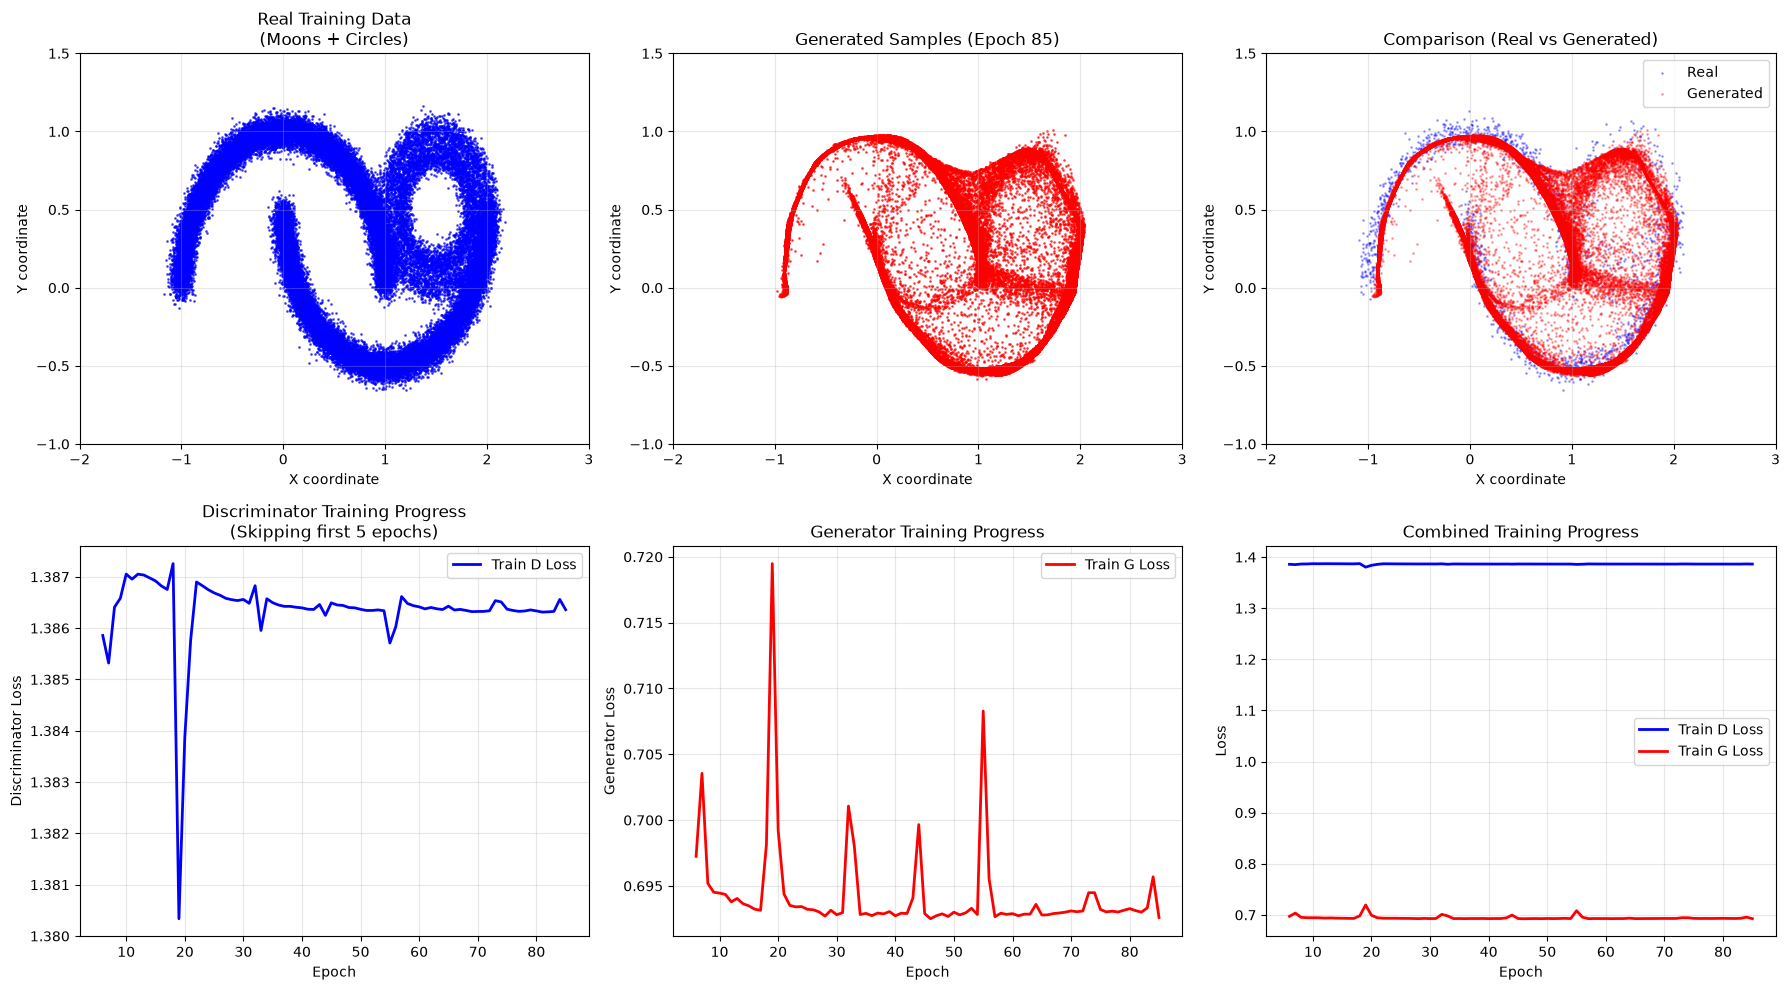

📈 Epoch 85 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3864
   Train G Loss: 0.6926, Val G Loss: 0.6929

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/50000 (0%)]	D_loss: 1.386215	G_loss: 0.693171
Epoch: 86 [6400/50000 (13%)]	D_loss: 1.386265	G_loss: 0.697689
Epoch: 86 [12800/50000 (26%)]	D_loss: 1.386741	G_loss: 0.690751
Epoch: 86 [19200/50000 (38%)]	D_loss: 1.386903	G_loss: 0.692407
Epoch: 86 [25600/50000 (51%)]	D_loss: 1.386373	G_loss: 0.698831
Epoch: 86 [32000/50000 (64%)]	D_loss: 1.386576	G_loss: 0.695255
Epoch: 86 [38400/50000 (77%)]	D_loss: 1.386266	G_loss: 0.688041
Epoch: 86 [44800/50000 (90%)]	D_loss: 1.386361	G_loss: 0.688209
====> Epoch: 86 Train D_loss: 1.3863, Train G_loss: 0.6930
====> Epoch: 86 Val D_loss: 1.3862, Val G_loss: 0.6967
📈 Epoch 86 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6930, Val G Loss: 0.6967

📊 Epoch 87/100
----------------------------------------
Epoch: 87 [0/50000 (0%)]	D_loss: 1.386131	G_loss: 

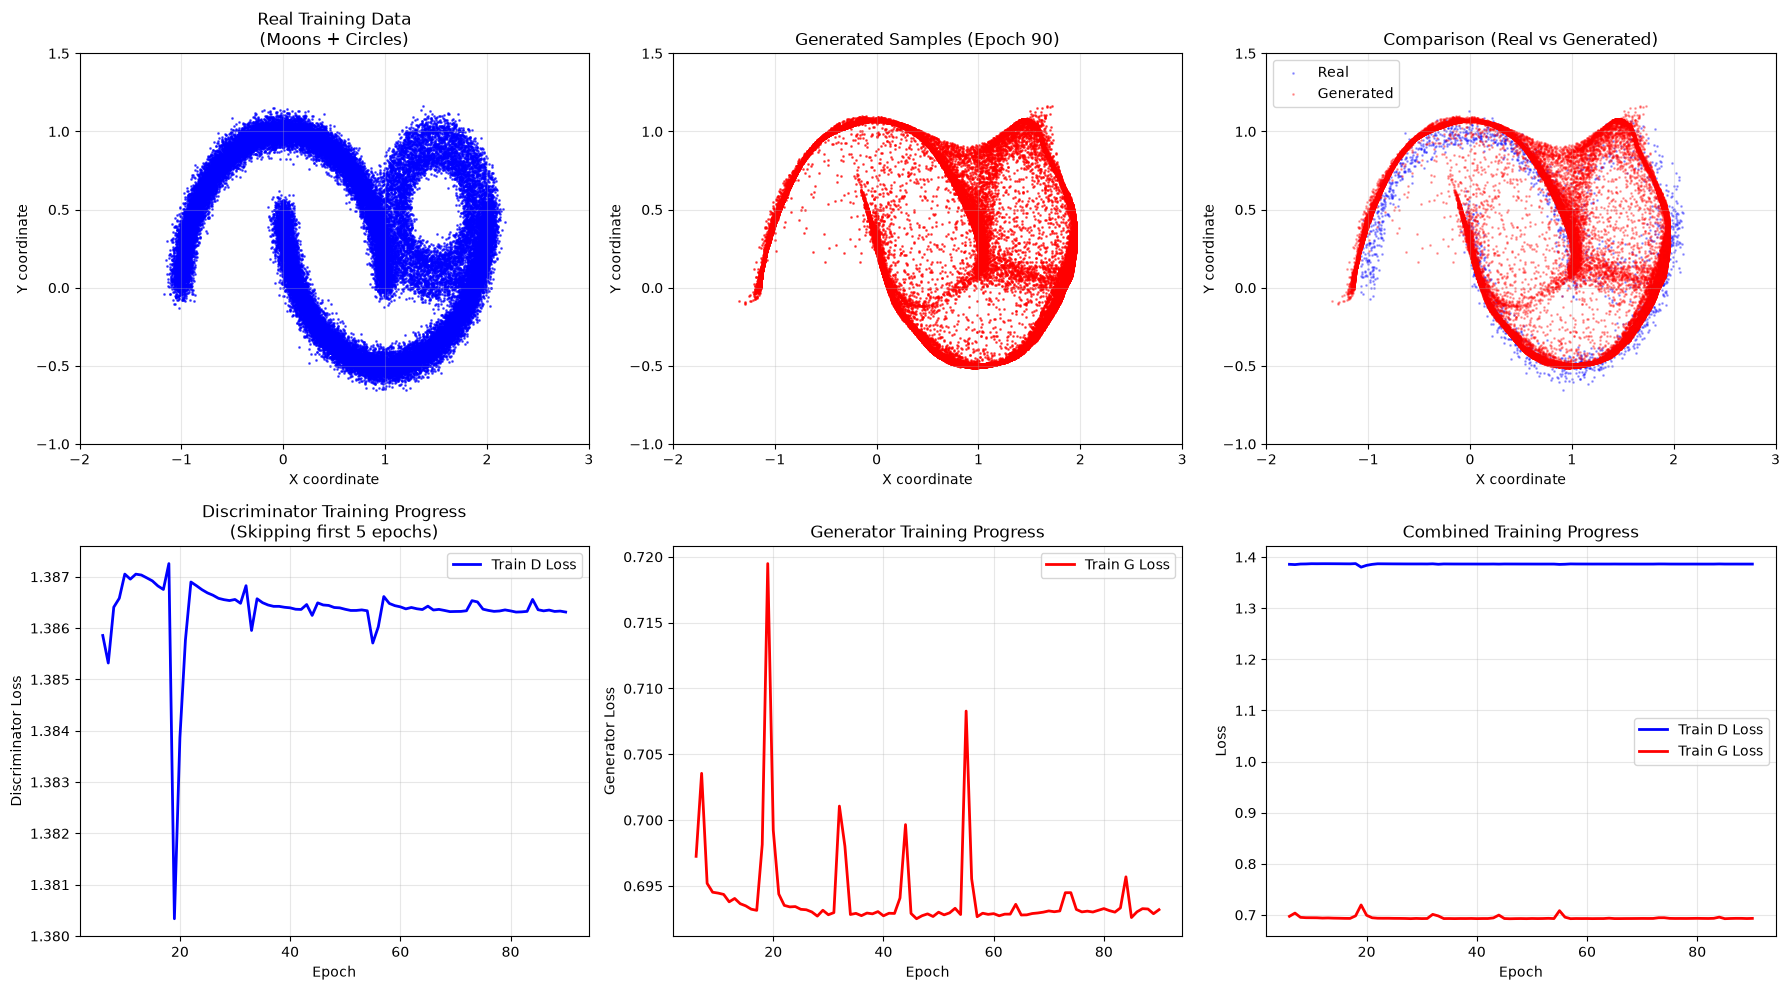

📈 Epoch 90 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932, Val G Loss: 0.6932

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/50000 (0%)]	D_loss: 1.386297	G_loss: 0.693187
Epoch: 91 [6400/50000 (13%)]	D_loss: 1.385975	G_loss: 0.689431
Epoch: 91 [12800/50000 (26%)]	D_loss: 1.386263	G_loss: 0.695300
Epoch: 91 [19200/50000 (38%)]	D_loss: 1.386932	G_loss: 0.691552
Epoch: 91 [25600/50000 (51%)]	D_loss: 1.386488	G_loss: 0.695222
Epoch: 91 [32000/50000 (64%)]	D_loss: 1.386486	G_loss: 0.694625
Epoch: 91 [38400/50000 (77%)]	D_loss: 1.386271	G_loss: 0.693201
Epoch: 91 [44800/50000 (90%)]	D_loss: 1.386461	G_loss: 0.695378
====> Epoch: 91 Train D_loss: 1.3863, Train G_loss: 0.6931
====> Epoch: 91 Val D_loss: 1.3864, Val G_loss: 0.6923
📈 Epoch 91 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6931, Val G Loss: 0.6923

📊 Epoch 92/100
----------------------------------------
Epoch: 92 [0/50000 (0%)]	D_loss: 1.386300	G_loss: 

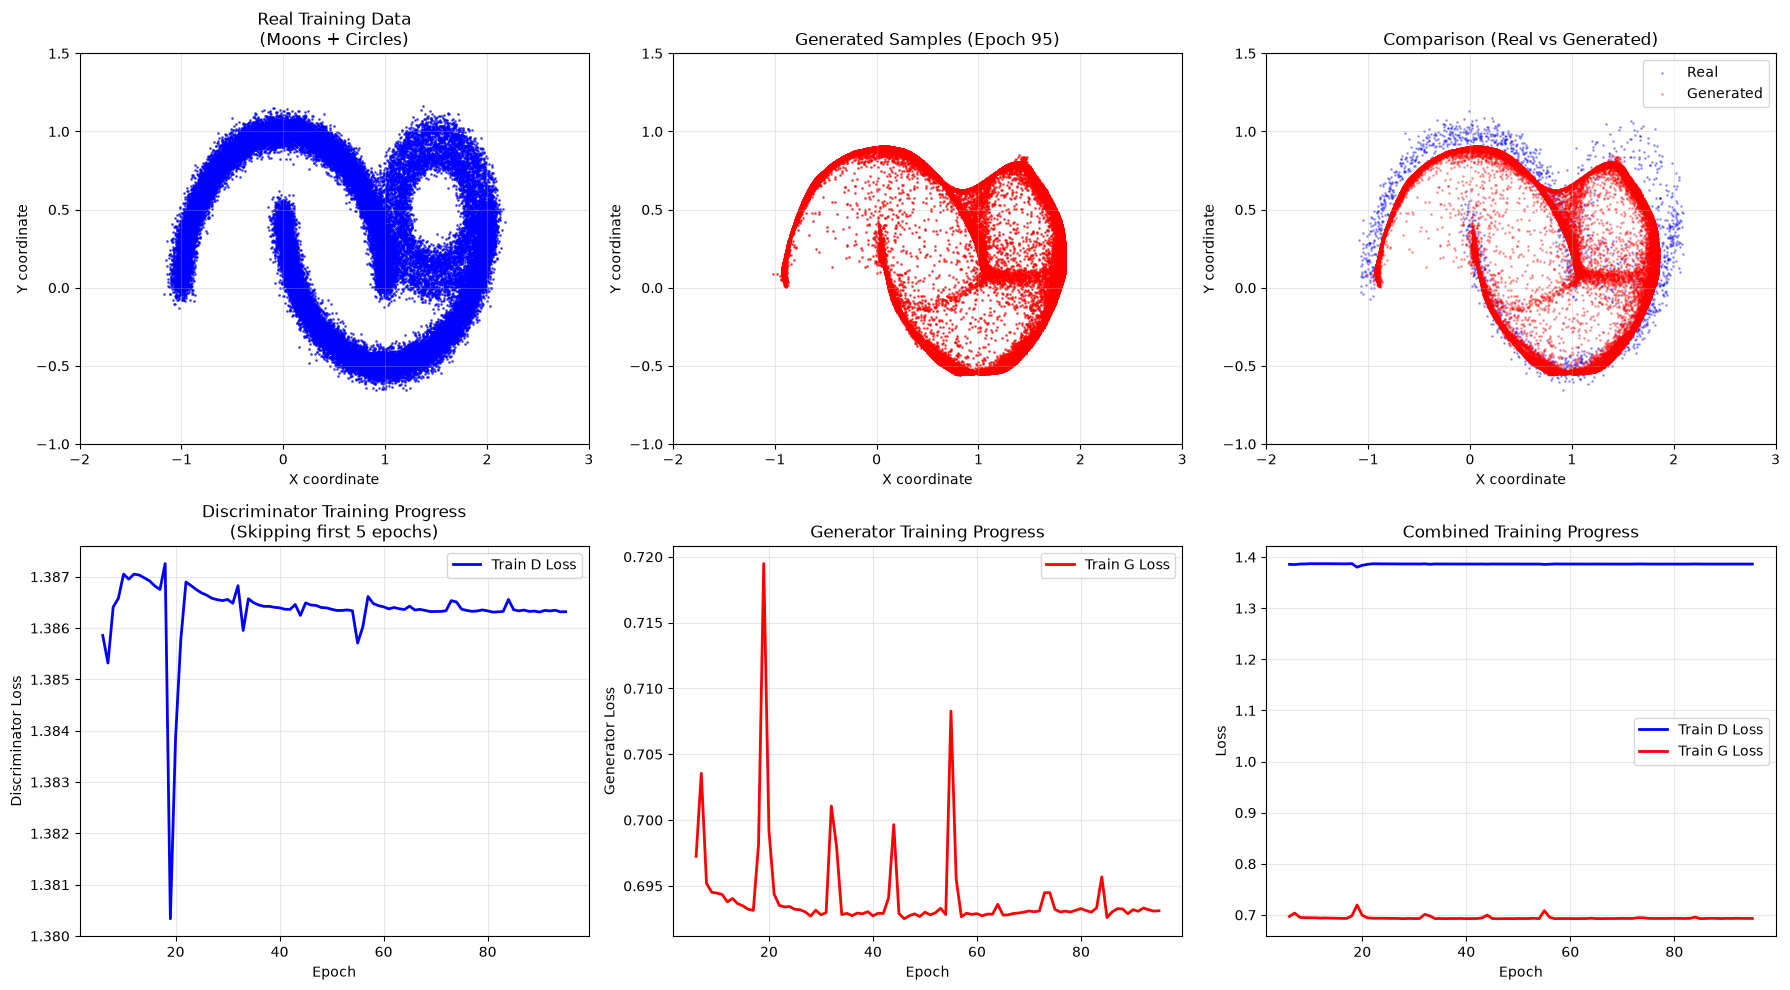

📈 Epoch 95 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3866
   Train G Loss: 0.6931, Val G Loss: 0.6913

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/50000 (0%)]	D_loss: 1.385843	G_loss: 0.691585
Epoch: 96 [6400/50000 (13%)]	D_loss: 1.386566	G_loss: 0.692976
Epoch: 96 [12800/50000 (26%)]	D_loss: 1.386298	G_loss: 0.692682
Epoch: 96 [19200/50000 (38%)]	D_loss: 1.386209	G_loss: 0.692946
Epoch: 96 [25600/50000 (51%)]	D_loss: 1.386120	G_loss: 0.692282
Epoch: 96 [32000/50000 (64%)]	D_loss: 1.386215	G_loss: 0.693833
Epoch: 96 [38400/50000 (77%)]	D_loss: 1.386141	G_loss: 0.696653
Epoch: 96 [44800/50000 (90%)]	D_loss: 1.386678	G_loss: 0.693478
====> Epoch: 96 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 96 Val D_loss: 1.3864, Val G_loss: 0.6931
📈 Epoch 96 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6933, Val G Loss: 0.6931

📊 Epoch 97/100
----------------------------------------
Epoch: 97 [0/50000 (0%)]	D_loss: 1.386442	G_loss: 

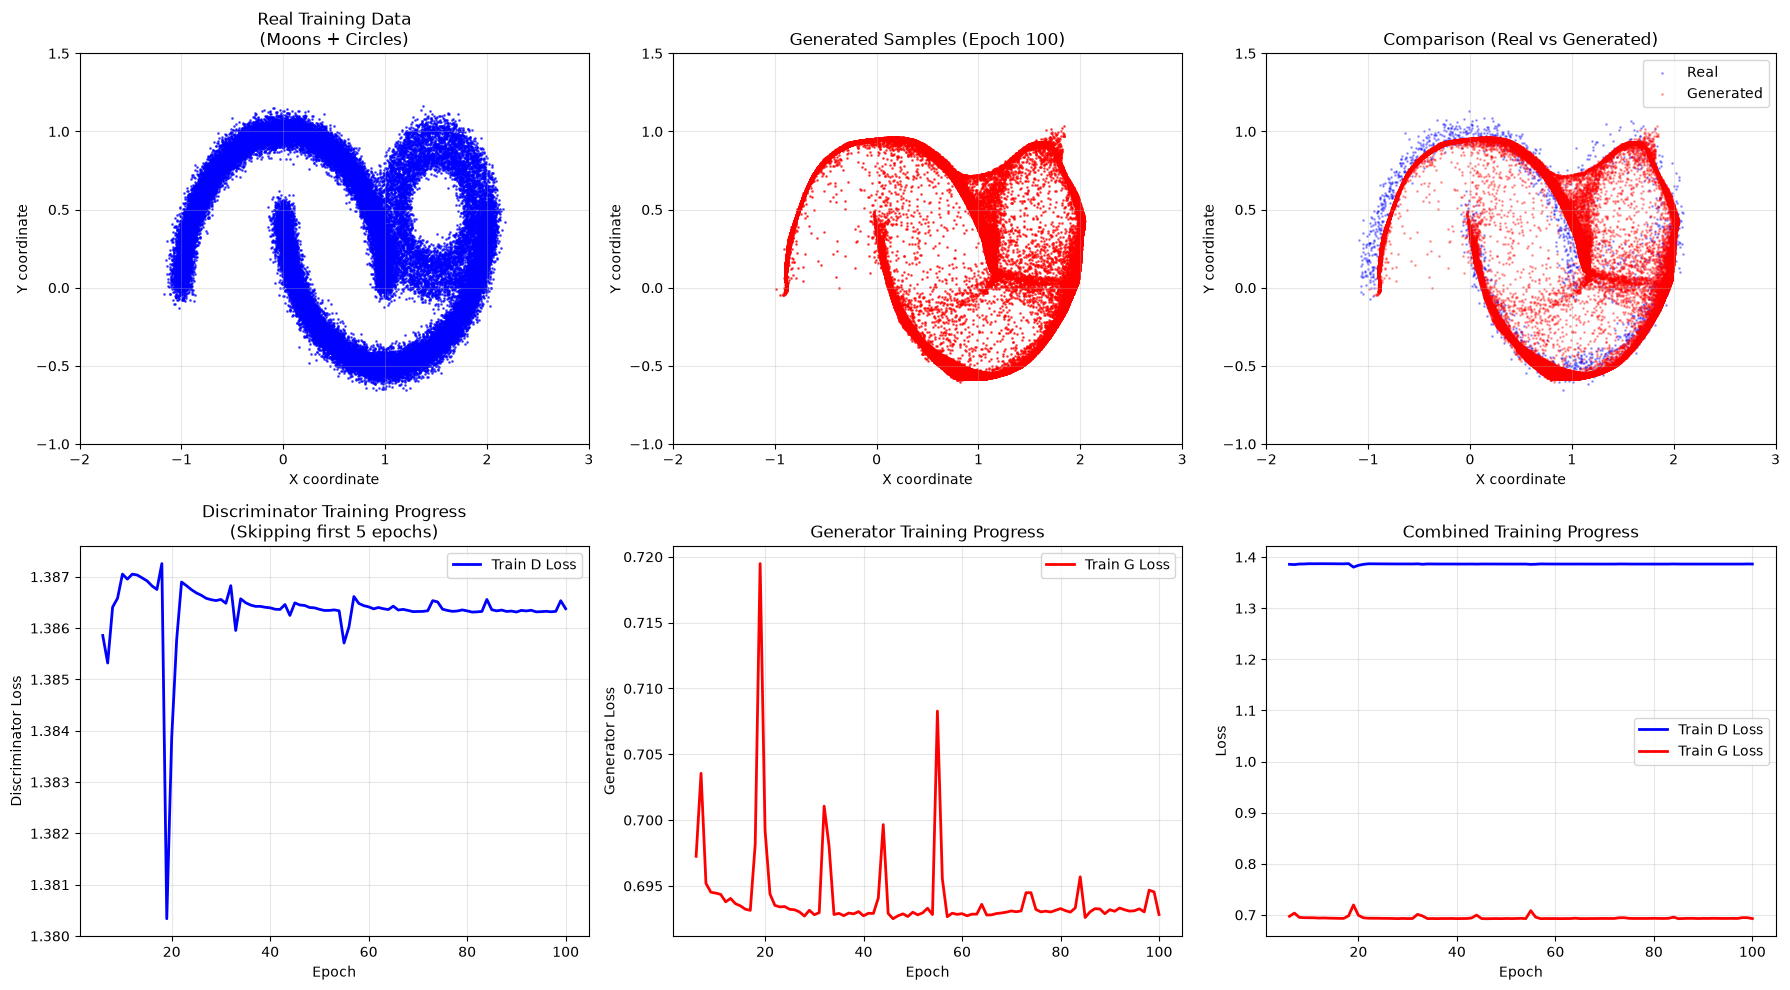

📈 Epoch 100 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3863
   Train G Loss: 0.6928, Val G Loss: 0.6913

🎉 Training completed!

🎨 Final comprehensive visualization:


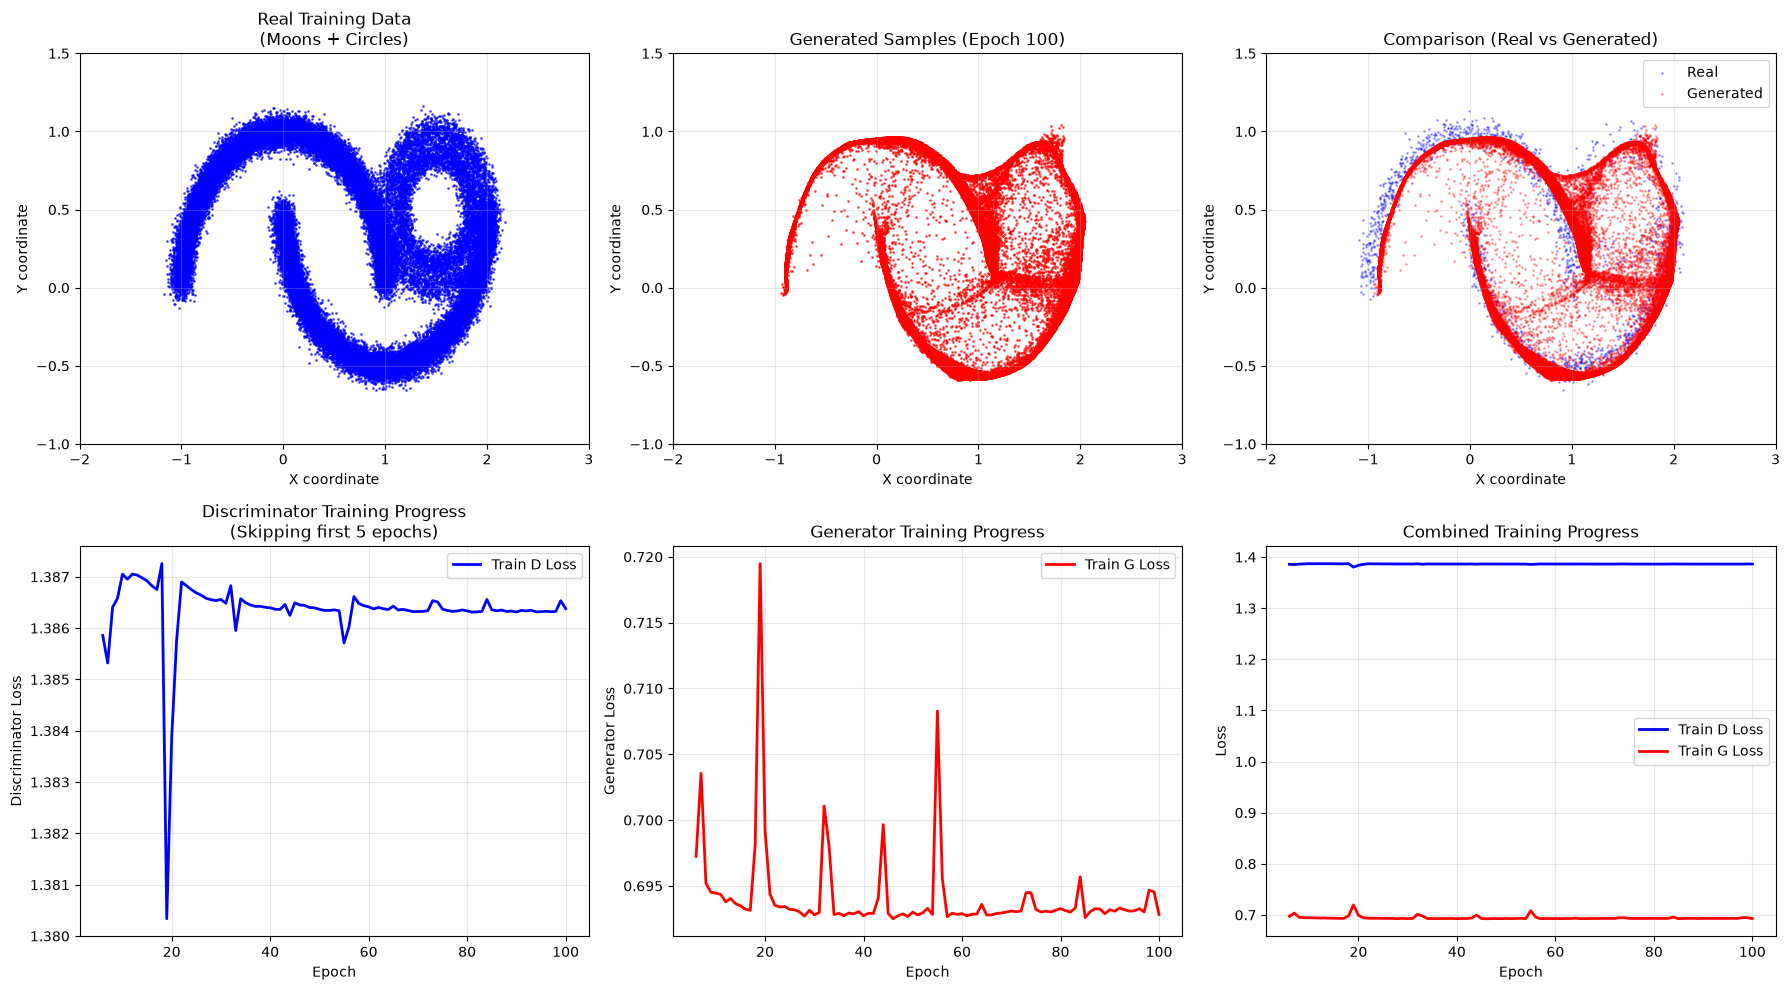

📊 Training progress visualized above!
   Watch how the losses change as the networks compete!
   The more challenging dataset should make training more interesting!


In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)

print("📊 Training progress visualized above!")
print("   Watch how the losses change as the networks compete!")
print("   The more challenging dataset should make training more interesting!")


## Step 9: Let's Generate New Data! 🎨

Now for the fun part - let's use our trained Generator to create new moon-shaped data! This demonstrates the power of GANs for generative modeling.


🎨 Generating new moon-shaped data...


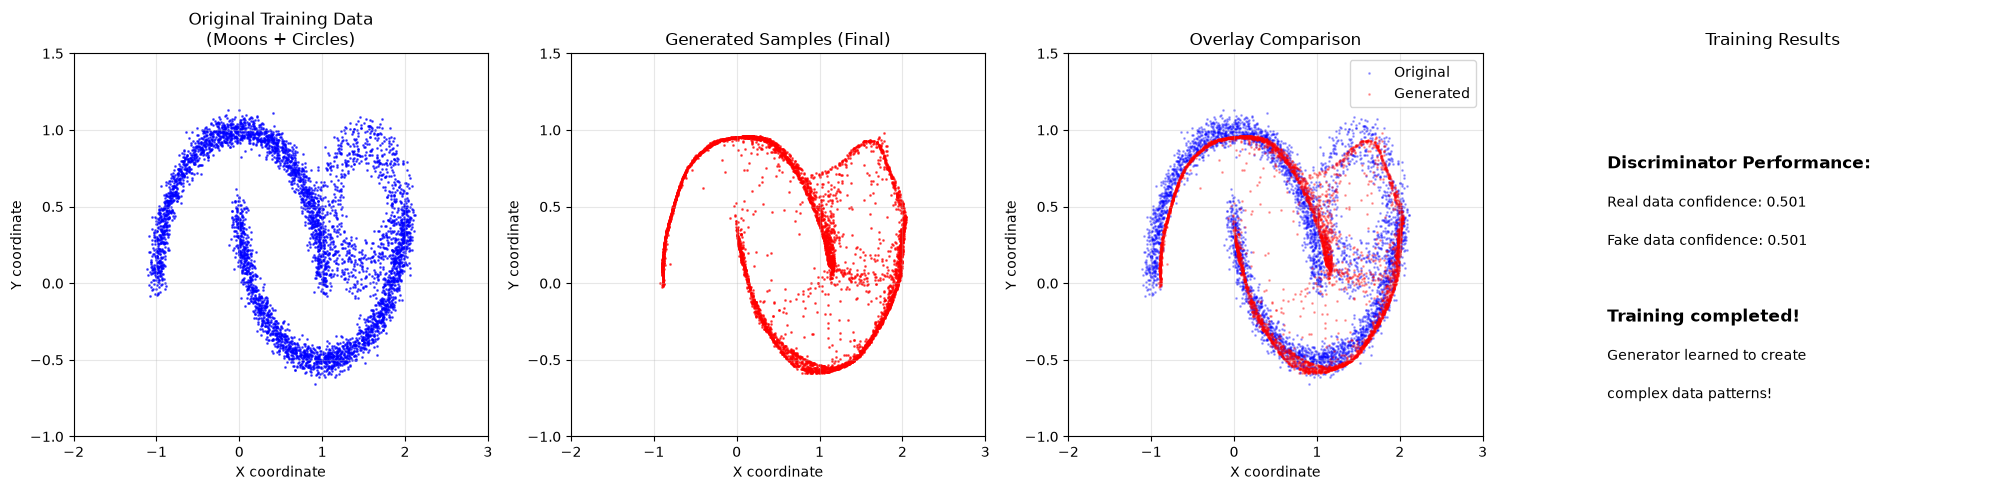

✅ New data generated!
   Compare the shapes - our Generator learned to create complex data patterns!
   The generated samples should capture both moon and circle structures.
   Discriminator confidence on real data: 0.501
   Discriminator confidence on fake data: 0.501
   The more challenging dataset made training more interesting!


In [15]:
# Generate new samples using our trained Generator
print("🎨 Generating new moon-shaped data...")

# Generate a large number of samples
fake_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 5))

# Original training data
plt.subplot(1, 4, 1)
plt.scatter(train_data[:5000, 0], train_data[:5000, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data\n(Moons + Circles)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.xlim(-2, 3)
plt.ylim(-1, 1.5)
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(1, 4, 2)
plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples (Final)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.xlim(-2, 3)
plt.ylim(-1, 1.5)
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(1, 4, 3)
plt.scatter(train_data[:5000, 0], train_data[:5000, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.xlim(-2, 3)
plt.ylim(-1, 1.5)
plt.legend()
plt.grid(True, alpha=0.3)

# Show the adversarial process
plt.subplot(1, 4, 4)
# Generate some samples and show discriminator predictions
generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = torch.from_numpy(train_data[:100]).to(device).float()
    real_pred = discriminator(real_batch).mean().item()
    
    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

plt.text(0.1, 0.7, f'Discriminator Performance:', fontsize=12, weight='bold')
plt.text(0.1, 0.6, f'Real data confidence: {real_pred:.3f}', fontsize=10)
plt.text(0.1, 0.5, f'Fake data confidence: {fake_pred:.3f}', fontsize=10)
plt.text(0.1, 0.3, f'Training completed!', fontsize=12, weight='bold')
plt.text(0.1, 0.2, f'Generator learned to create', fontsize=10)
plt.text(0.1, 0.1, f'complex data patterns!', fontsize=10)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.axis('off')
plt.title('Training Results')

plt.tight_layout()
plt.show()

print("✅ New data generated!")
print("   Compare the shapes - our Generator learned to create complex data patterns!")
print("   The generated samples should capture both moon and circle structures.")
print(f"   Discriminator confidence on real data: {real_pred:.3f}")
print(f"   Discriminator confidence on fake data: {fake_pred:.3f}")
print("   The more challenging dataset made training more interesting!")


## 🎉 Congratulations! You've Built a GAN!

You've successfully implemented and trained a Generative Adversarial Network (GAN)! Let's summarize what we accomplished:

### What We Learned:
1. **GANs**: Two competing neural networks that improve together
2. **Generator**: Creates fake data from random noise
3. **Discriminator**: Distinguishes between real and fake data
4. **Adversarial Training**: The competitive process that drives learning
5. **Loss Functions**: How to measure and optimize the adversarial game

### Key Concepts:
- **Adversarial Loss**: Generator and Discriminator have opposing objectives
- **Training Balance**: Both networks must improve together
- **Mode Collapse**: A common GAN problem where the generator produces limited variety
- **Convergence**: The ideal state where both networks reach equilibrium

### What Makes GANs Special:
- ✅ **No Explicit Likelihood**: GANs don't need to model the data distribution explicitly
- ✅ **High-Quality Samples**: Can generate very realistic data
- ✅ **Flexible Architecture**: Can be applied to many different data types
- ✅ **Implicit Learning**: Learns the data distribution through adversarial training


## 🚀 Next Steps and Experiments

Now that you understand the basics, here are some exciting experiments you can try:

### Easy Experiments:
1. **Change the Dataset**: Try different datasets like circles, spirals, or your own 2D data
2. **Adjust Hyperparameters**: 
   - Change learning rates (try 1e-3, 1e-5)
   - Modify network sizes (try 128, 512 hidden units)
   - Adjust training epochs (try 50, 200)
3. **Visualize Training**: Watch how the generated samples evolve during training

### Intermediate Experiments:
4. **Different Architectures**: Try deeper networks or different activation functions
5. **Training Balance**: Experiment with training the discriminator more/less than the generator
6. **Noise Dimensions**: Try different noise input sizes (1D, 3D, 4D)

### Advanced Experiments:
7. **Conditional GANs**: Generate different types of data based on labels
8. **Wasserstein GAN**: Implement the more stable WGAN loss function
9. **Higher Dimensions**: Apply to image data or other high-dimensional problems

### Code Modifications to Try:
```python
# Try different datasets
from sklearn.datasets import make_circles, make_spiral
train_data = make_circles(n_samples=50000, noise=0.05)[0].astype(np.float32)

# Try different architectures
HIDDEN_DIM = 512      # Larger networks
NOISE_DIM = 4         # Different noise dimensions

# Try different learning rates
LR_G = 1e-3           # Higher learning rate
LR_D = 1e-4           # Different rates for G and D
```


## 📚 Further Reading and Resources

### Papers to Read:
1. **Original GAN Paper**: "Generative Adversarial Networks" by Goodfellow et al. (2014)
2. **DCGAN**: "Unsupervised Representation Learning with Deep Convolutional GANs" by Radford et al. (2016)
3. **WGAN**: "Wasserstein GAN" by Arjovsky et al. (2017)
4. **Progressive GAN**: "Progressive Growing of GANs" by Karras et al. (2018)

### Libraries to Explore:
- **PyTorch GAN Zoo**: Collection of GAN implementations
- **StyleGAN**: Advanced GAN for high-quality image generation
- **BigGAN**: Large-scale GAN training techniques

### Applications:
- **Image Generation**: Creating realistic images from scratch
- **Data Augmentation**: Generating more training data
- **Style Transfer**: Changing the style of images
- **Super-Resolution**: Enhancing image quality
- **Text-to-Image**: Generating images from text descriptions

### Key Takeaways:
- GANs are powerful tools for generative modeling
- The adversarial training process is key to their success
- Training stability is crucial - many techniques exist to improve it
- GANs can generate high-quality, diverse samples
- The balance between Generator and Discriminator is critical

### Common GAN Challenges:
- **Mode Collapse**: Generator produces limited variety
- **Training Instability**: Losses can oscillate or diverge
- **Evaluation**: Hard to measure GAN quality objectively
- **Hyperparameter Sensitivity**: Small changes can have big effects

---

**Happy Learning! 🎓**

*Remember: The best way to learn is by experimenting. Try modifying the code, changing parameters, and seeing what happens. Every experiment teaches you something new about how GANs work!*
